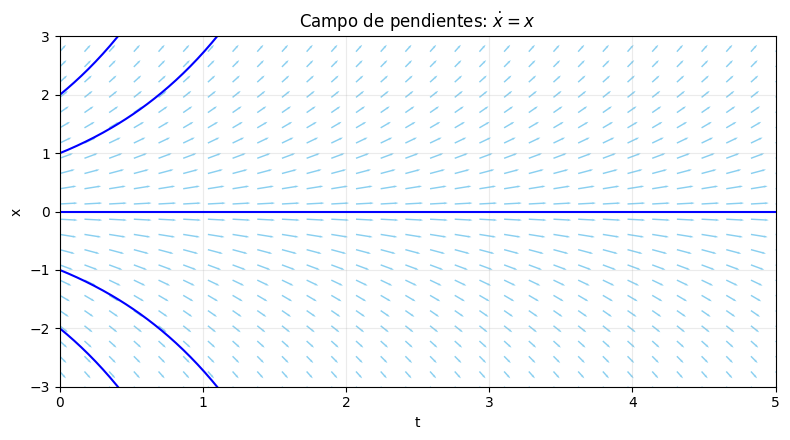

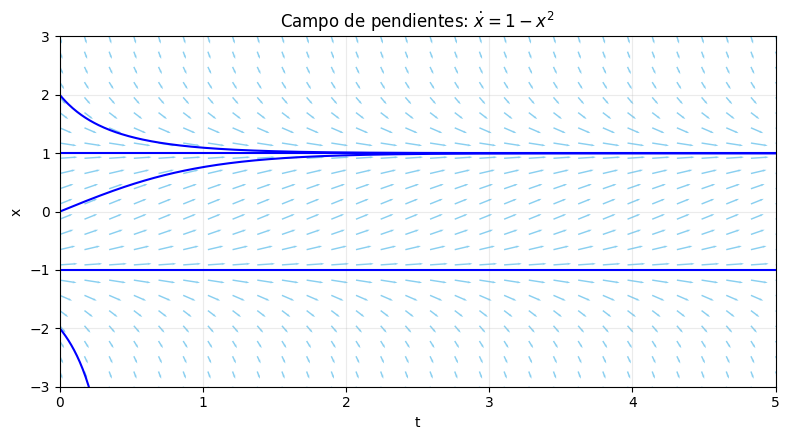

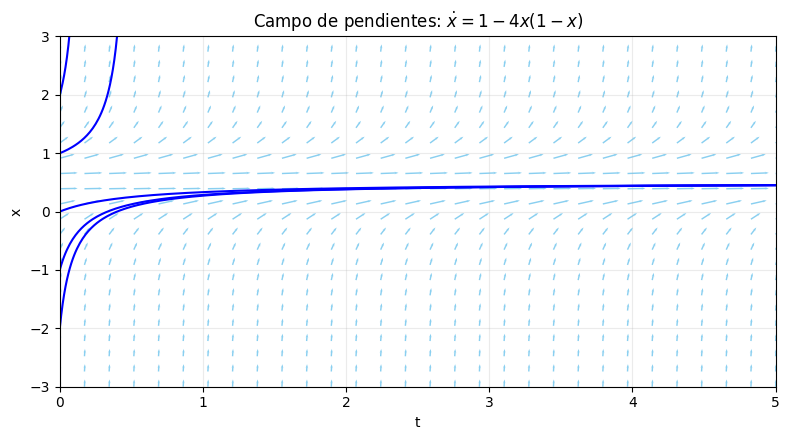

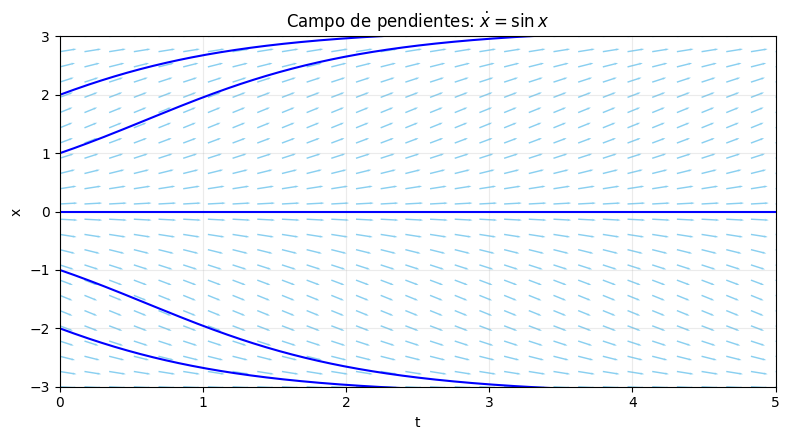

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------------------------
# Parámetros del campo
# ---------------------------
nt, nx = 30, 24
t_min, t_max = 0.0, 5.0
x_min, x_max = -3.0, 3.0

arrow_color = "#89CFF0"    # flechas azul claro
arrow_width = 0.002
arrow_scale = 8
headwidth = 2
headlength = 3
headaxislength = 2

# ---------------------------
# Definición de las funciones
# ---------------------------
def f_a(x): return x
def f_b(x): return 1 - x**2
def f_c(x): return 1 - 4*x*(1 - x)
def f_d(x): return np.sin(x)

funcs = [
    (f_a, r"$\dot x = x$"),
    (f_b, r"$\dot x = 1 - x^2$"),
    (f_c, r"$\dot x = 1 - 4x(1-x)$"),
    (f_d, r"$\dot x = \sin x$"),
]

# ---------------------------
# Malla para el campo
# ---------------------------
T = np.linspace(t_min, t_max, nt)
X = np.linspace(x_min, x_max, nx)
TT, XX = np.meshgrid(T, X)

# ---------------------------
# Dibujar cada sistema
# ---------------------------
for f, title in funcs:
    F = f(XX)
    U = np.ones_like(F)
    V = F

    mag = np.sqrt(U**2 + V**2)
    mag[mag == 0] = 1.0
    U2 = U / mag
    V2 = V / mag

    plt.figure(figsize=(8, 4.5))
    plt.quiver(TT, XX, U2, V2,
               angles='xy', scale_units='xy', scale=arrow_scale,
               width=arrow_width, color=arrow_color,
               headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
               pivot='tail')

    # ---------------------------
    # Trayectorias de integración (curvas azules)
    # ---------------------------
    def ode(t, x): return f(x)

    # condiciones iniciales de prueba (puedes cambiarlas)
    x0_values = [-2, -1, 0, 1, 2]

    for x0 in x0_values:
        sol = solve_ivp(ode, [t_min, t_max], [x0], dense_output=True, max_step=0.05)
        t_vals = np.linspace(t_min, t_max, 500)
        x_vals = sol.sol(t_vals)[0]
        plt.plot(t_vals, x_vals, color="blue", linewidth=1.5)

    plt.xlim(t_min, t_max)
    plt.ylim(x_min, x_max)
    plt.xlabel('t')
    plt.ylabel('x')
    plt.title(f'Campo de pendientes: {title}')
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()






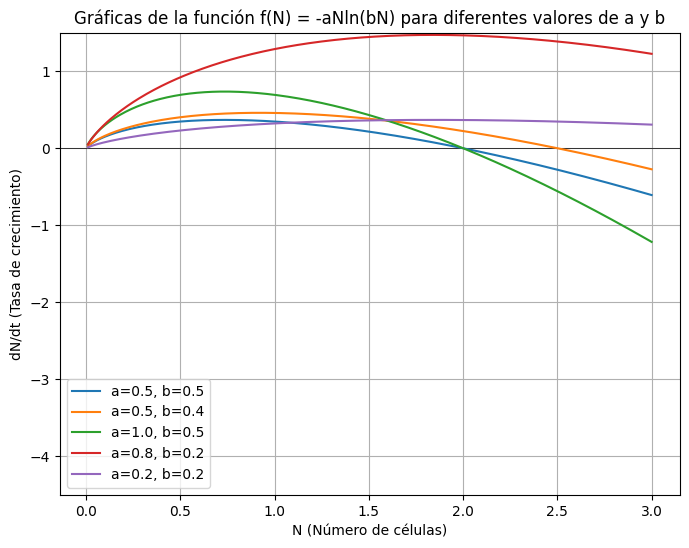

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Función de Gompertz: dN/dt = f(N)
def gompertz_f(N, a, b):
    # Se usa np.log para el logaritmo natural (ln)
    return -a * N * np.log(b * N)

# Rango de N para graficar
N_vals = np.linspace(0.01, 3.0, 300) # Evitar N=0 para el logaritmo

# Definición de diferentes parámetros (a, b) para simular diferentes curvas
parametros = [
    (0.5, 0.5, 'a=0.5, b=0.5'),
    (0.5, 0.4, 'a=0.5, b=0.4'),
    (1.0, 0.5, 'a=1.0, b=0.5'),
    (0.8, 0.2, 'a=0.8, b=0.2'),
    (0.2, 0.2, 'a=0.2, b=0.2'),
]

plt.figure(figsize=(8, 6))
plt.grid(True)
plt.axhline(0, color='black', linewidth=0.5) # Eje horizontal dN/dt = 0

for a, b, label in parametros:
    dN_dt_vals = gompertz_f(N_vals, a, b)
    plt.plot(N_vals, dN_dt_vals, label=label)

plt.xlabel('N (Número de células)')
plt.ylabel('dN/dt (Tasa de crecimiento)')
plt.title('Gráficas de la función f(N) = -aNln(bN) para diferentes valores de a y b')
plt.legend()
plt.ylim(-4.5, 1.5) # Ajuste de límites para que se parezca a tu figura
plt.show()

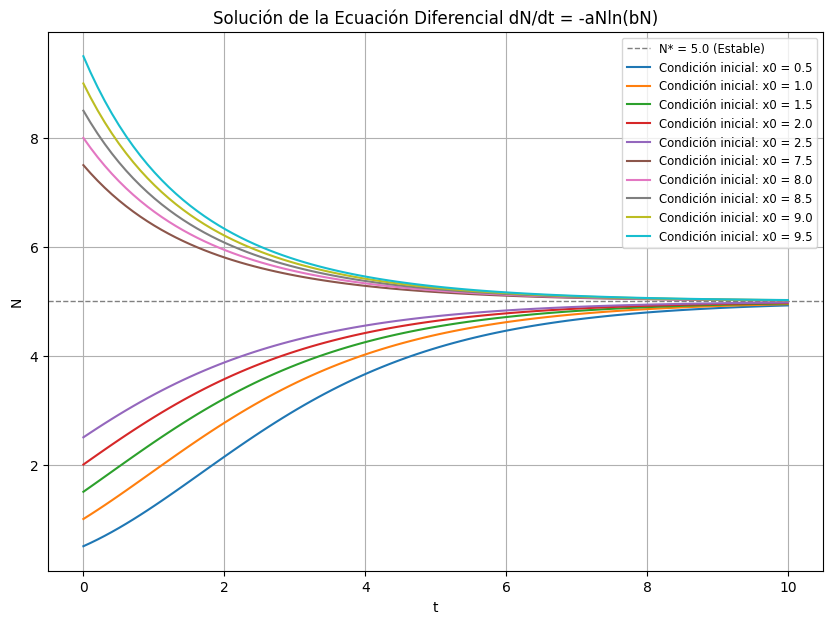

In [ ]:
from scipy.integrate import odeint
import numpy as np
import matplotlib.pyplot as plt

# Parámetros fijos para la simulación
a = 0.5
b = 0.2
N_star = 1 / b # N* = 5

# Ecuación diferencial (la función debe recibir (N, t))
def gompertz_ode(N, t):
    # Condición de guardia para evitar problemas con ln(N<=0)
    if N <= 0:
        return 0
    return -a * N * np.log(b * N)

# Vector de tiempo
t = np.linspace(0, 10, 100)

# Condiciones iniciales para la simulación
N0_vals = [0.5, 1.0, 1.5, 2.0, 2.5, 7.5, 8.0, 8.5, 9.0, 9.5]

plt.figure(figsize=(10, 7))
plt.grid(True)
plt.axhline(N_star, color='gray', linestyle='--', linewidth=1, label=f'N* = {N_star} (Estable)') # Línea de equilibrio

for N0 in N0_vals:
    # Resolver la EDO para cada condición inicial
    N_sol = odeint(gompertz_ode, N0, t)

    # Extraer la solución aplanando el array
    plt.plot(t, N_sol.flatten(), label=f'Condición inicial: x0 = {N0}')

plt.xlabel('t')
plt.ylabel('N')
plt.title('Solución de la Ecuación Diferencial dN/dt = -aNln(bN)')
plt.legend(loc='upper right', fontsize='small')
plt.show()

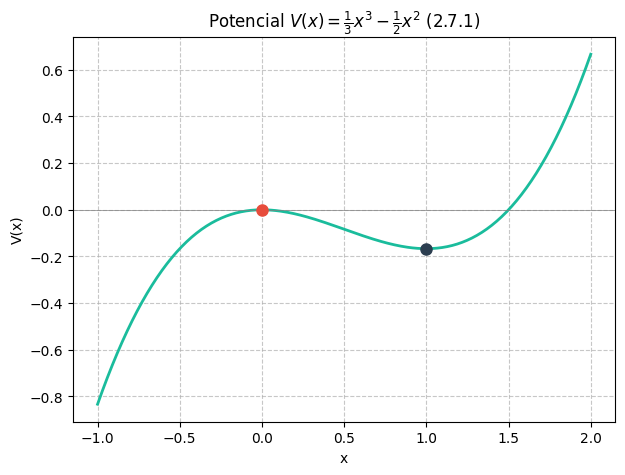

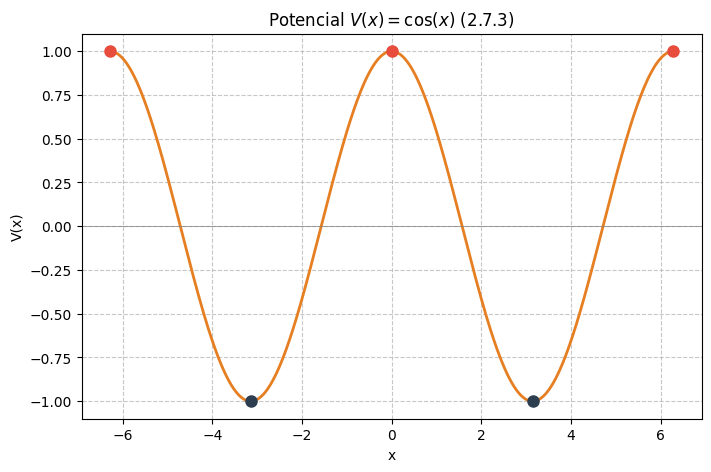

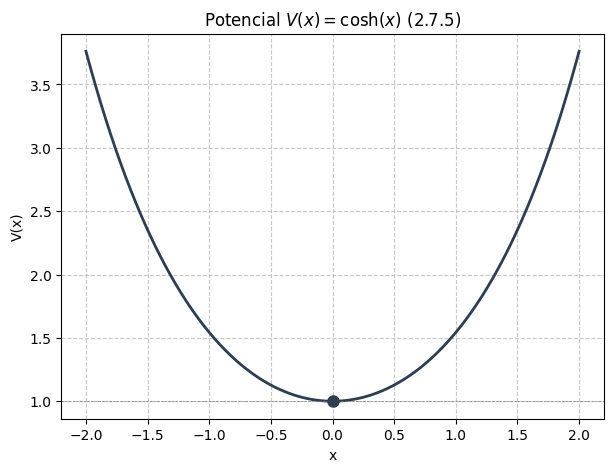

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Colores personalizados ---
COLOR_ESTABLE = '#2c3e50' # Azul Marino (Mínimos)
COLOR_INESTABLE = '#e74c3c' # Rojo Ladrillo (Máximos)
COLOR_LINEA_1 = '#1abc9c' # Verde Esmeralda
COLOR_LINEA_3 = '#e67e22' # Naranja Quemado/Terracota
COLOR_LINEA_5 = '#2c3e50' # Azul Marino

# =======================================================
# 2.7.1: V(x) = (1/3)x^3 - (1/2)x^2
# =======================================================
def V_271(x):
    return (1/3) * x**3 - (1/2) * x**2

x_271 = np.linspace(-1.0, 2.0, 300)
V_271_vals = V_271(x_271)
# Puntos fijos: (x*, V(x*), estabilidad)
puntos_fijos_271 = [(0.0, V_271(0.0), 'inestable'), (1.0, V_271(1.0), 'estable')]

plt.figure(figsize=(7, 5))
plt.plot(x_271, V_271_vals, color=COLOR_LINEA_1, linewidth=2)
plt.xlabel('x')
plt.ylabel('V(x)')
plt.title(r'Potencial $V(x) = \frac{1}{3}x^3 - \frac{1}{2}x^2$ (2.7.1)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(0, color='gray', linewidth=0.5)

for x_star, V_star, estabilidad in puntos_fijos_271:
    color = COLOR_ESTABLE if estabilidad == 'estable' else COLOR_INESTABLE
    plt.plot(x_star, V_star, 'o', color=color, markersize=8)

plt.savefig('grafica_2.7.1_potencial.png')


# =======================================================
# 2.7.3: V(x) = cos(x)
# =======================================================
def V_273(x):
    return np.cos(x)

x_273 = np.linspace(-2*np.pi, 2*np.pi, 500)
V_273_vals = V_273(x_273)
# Puntos fijos: Se muestran los principales en el rango
puntos_fijos_273 = [(-2*np.pi, 1.0, 'inestable'), (-np.pi, -1.0, 'estable'),
                    (0.0, 1.0, 'inestable'), (np.pi, -1.0, 'estable'), (2*np.pi, 1.0, 'inestable')]

plt.figure(figsize=(8, 5))
plt.plot(x_273, V_273_vals, color=COLOR_LINEA_3, linewidth=2)
plt.xlabel('x')
plt.ylabel('V(x)')
plt.title(r'Potencial $V(x) = \cos(x)$ (2.7.3)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(0, color='gray', linewidth=0.5)

for x_star, V_star, estabilidad in puntos_fijos_273:
    color = COLOR_ESTABLE if estabilidad == 'estable' else COLOR_INESTABLE
    plt.plot(x_star, V_star, 'o', color=color, markersize=8)

plt.savefig('grafica_2.7.3_potencial.png')


# =======================================================
# 2.7.5: V(x) = cosh(x)
# =======================================================
def V_275(x):
    return np.cosh(x)

x_275 = np.linspace(-2.0, 2.0, 300)
V_275_vals = V_275(x_275)
# Punto fijo: (0, 1) estable (mínimo global)
puntos_fijos_275 = [(0.0, V_275(0.0), 'estable')]

plt.figure(figsize=(7, 5))
plt.plot(x_275, V_275_vals, color=COLOR_LINEA_5, linewidth=2)
plt.xlabel('x')
plt.ylabel('V(x)')
plt.title(r'Potencial $V(x) = \cosh(x)$ (2.7.5)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(1.0, color='gray', linestyle='--', linewidth=0.5)

for x_star, V_star, estabilidad in puntos_fijos_275:
    color = COLOR_ESTABLE if estabilidad == 'estable' else COLOR_INESTABLE
    plt.plot(x_star, V_star, 'o', color=color, markersize=8)

plt.savefig('grafica_2.7.5_potencial.png')


# MOSTRAR TODAS LAS GRÁFICAS JUNTAS
plt.show()

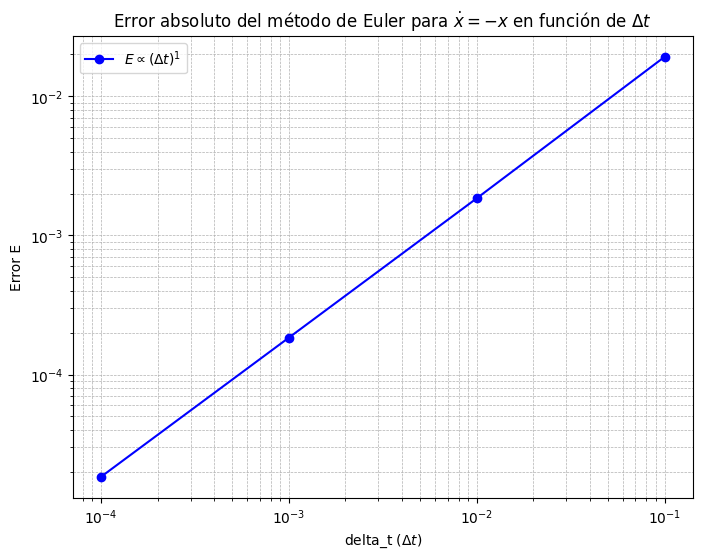

In [ ]:
## 2. Código Python para la Gráfica del Error (Parte c)

##Aquí tienes el código Python que calcula los valores de $\hat{x}(1)$ usando el método de Euler y luego grafica el error $E$ vs. $\Delta t$ en una escala logarítmica, tal como se pide en el ejercicio.

##```python
import numpy as np
import matplotlib.pyplot as plt

# --- (a) Valor exacto ---
x_exacto = np.exp(-1) # e^-1

# --- (b) Parámetros de simulación ---
delta_t_vals = np.array([1.0, 1e-1, 1e-2, 1e-3, 1e-4]) # Valores de Delta t a probar
x0 = 1.0 # Condición inicial x(0)=1
T_final = 1.0 # Tiempo final

# --- Implementación del método de Euler ---
def euler_method(f, x0, dt, t_final):
    """Resuelve dx/dt = f(x) usando el método de Euler."""
    num_steps = int(t_final / dt)
    x = x0
    for _ in range(num_steps):
        # f(x) = -x para este problema
        x += f(x) * dt
    return x

# EDO: f(x) = -x
f_ode = lambda x: -x

# --- Calcular resultados numéricos y errores ---
x_euler_vals = []
error_vals = []

for dt in delta_t_vals:
    x_approx = euler_method(f_ode, x0, dt, T_final)
    x_euler_vals.append(x_approx)

    # Excluir el primer valor (dt=1.0) para el gráfico log-log,
    # ya que es una aproximación muy gruesa que no sigue la ley de potencias bien.
    if dt < 1.0:
        error = np.abs(x_approx - x_exacto)
        error_vals.append(error)

# --- Preparar datos para el gráfico log-log (omitiendo dt=1.0) ---
dt_log_vals = delta_t_vals[1:]
error_log_vals = np.array(error_vals)


# --- (c) Gráfico del Error E vs. Delta t ---
plt.figure(figsize=(8, 6))

# Título y etiquetas
plt.title(r'Error absoluto del método de Euler para $\dot{x}=-x$ en función de $\Delta t$')
plt.xlabel(r'delta_t ($\Delta t$)')
plt.ylabel(r'Error E')

# Establecer ambas escalas a logarítmica
plt.xscale('log')
plt.yscale('log')
plt.grid(True, which="both", linestyle='--', linewidth=0.5)

# Graficar los puntos y la línea
plt.plot(dt_log_vals, error_log_vals, marker='o', linestyle='-', color='blue')

# Opcional: Graficar el primer punto (dt=1) para referencia, si se desea
# E_dt_1 = np.abs(x_euler_vals[0] - x_exacto)
# plt.plot(delta_t_vals[0], E_dt_1, marker='x', color='red', label=r'Punto $\Delta t=1$')

plt.legend([r'$E \propto (\Delta t)^1$'], loc='upper left')
plt.savefig('grafica_2.8.3_error_log.png')
plt.show()

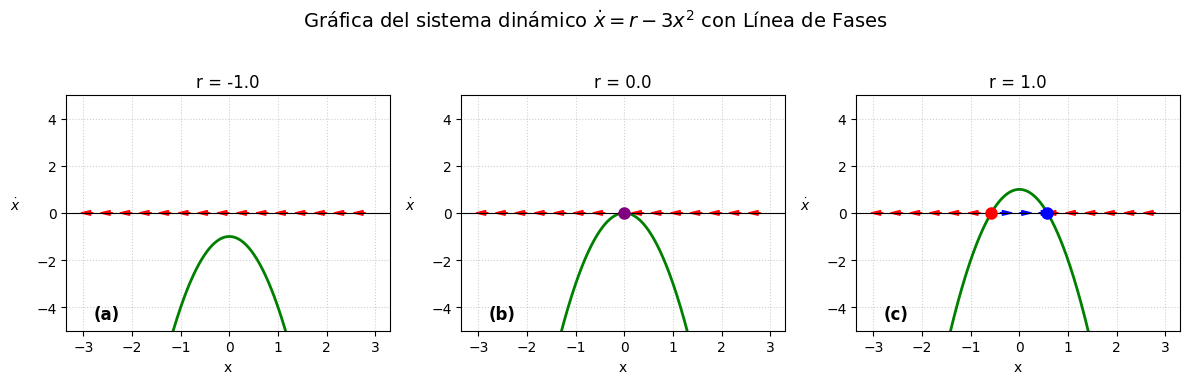

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    return r - 3 * x**2

# --- Parámetros y rangos ---
r_vals_plot = [-1.0, 0.0, 1.0] # Valores de r para el campo vectorial: (a), (b), (c)
x_vals = np.linspace(-3.0, 3.0, 400) # Rango de x para graficar

# --- Gráfica: Campo Vectorial para diferentes r con flechas de flujo ---
plt.figure(figsize=(12, 4))
plt.suptitle(r'Gráfica del sistema dinámico $\dot{x} = r - 3x^2$ con Línea de Fases', fontsize=14)

# Parámetros para las flechas de flujo
num_arrows = 15 # Cantidad de flechas a dibujar
arrow_length = 0.25 # Longitud visual de la flecha

for i, r in enumerate(r_vals_plot):
    plt.subplot(1, 3, i + 1)

    # Calcular f(x)
    f_vals = f(x_vals, r)

    # 1. Graficar f(x) vs x
    plt.plot(x_vals, f_vals, color='green', linewidth=2)

    # Línea del eje x (donde d(x)/dt = 0)
    plt.axhline(0, color='black', linewidth=0.8)

    # --- 2. Dibujar las flechas de la Línea de Fases (en el eje horizontal) ---

    # Puntos donde dibujaremos las flechas
    x_arrow_pos = np.linspace(x_vals.min() + 0.2, x_vals.max() - 0.2, num_arrows)

    # Calcular la dirección del flujo (x_dot) en esos puntos
    x_dot_at_arrows = f(x_arrow_pos, r)

    # El signo de x_dot determina la dirección (derecha si > 0, izquierda si < 0)
    for x_pos, x_dot in zip(x_arrow_pos, x_dot_at_arrows):

        # Determinar si la flecha va a la derecha (positivo) o izquierda (negativo)
        if x_dot > 1e-3: # Flujo positivo (derecha)
            direction = 1
            color = 'blue'
        elif x_dot < -1e-3: # Flujo negativo (izquierda)
            direction = -1
            color = 'red'
        else: # Cerca de un punto fijo, no dibujar flecha grande
            direction = 0
            color = 'purple'

        if direction != 0:
            # Dibujar la flecha usando plt.arrow
            plt.arrow(
                x_pos, 0.0,                           # Coordenada inicial (x, y=0)
                direction * arrow_length, 0.0,        # Vector de cambio (dx, dy=0)
                head_width=0.2, head_length=0.2,      # Tamaño de la cabeza
                fc=color, ec=color, linewidth=1,      # Color de relleno y borde
                length_includes_head=True             # Incluir la cabeza en la longitud total
            )

    # --- 3. Marcar los Puntos Fijos ---
    if r > 0:
        x_estable = np.sqrt(r / 3)
        x_inestable = -np.sqrt(r / 3)

        # Inestable (Rojo)
        plt.plot(x_inestable, 0, 'o', color='red', markersize=8, zorder=5)
        # Estable (Azul)
        plt.plot(x_estable, 0, 'o', color='blue', markersize=8, zorder=5)

    elif r == 0:
        # Punto de Silla-Nodo (Morado)
        plt.plot(0, 0, 'o', color='purple', markersize=8, zorder=5)

    # Etiquetas y título del subgráfico
    plt.title(f'r = {r}')
    plt.xlabel('x')
    plt.ylabel(r'$\dot{x}$', rotation=0, labelpad=15)
    plt.ylim(-5, 5)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.text(x_vals.min() + 0.2, -4.5, f'({chr(97+i)})', fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

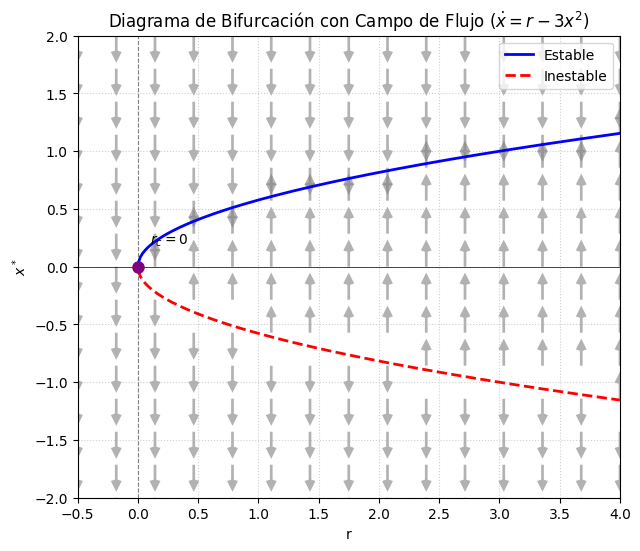

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    return r - 3 * x**2

# --- Parámetros para el diagrama de bifurcación ---
r_min, r_max = -0.5, 4.0
x_min, x_max = -2.0, 2.0

# Rango de r para los puntos fijos
r_bif_vals = np.linspace(0.001, r_max, 200) # r > 0 para los puntos fijos reales

# Puntos fijos para r > 0
x_estable_vals = np.sqrt(r_bif_vals / 3)
x_inestable_vals = -np.sqrt(r_bif_vals / 3)

plt.figure(figsize=(7, 6))
plt.title(r'Diagrama de Bifurcación con Campo de Flujo ($\dot{x} = r - 3x^2$)')
plt.xlabel('r')
plt.ylabel(r'$x^*$')
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8) # Línea en r=0
plt.axhline(0, color='black', linewidth=0.5)

# --- Dibujar los puntos fijos (curvas) ---
plt.plot(r_bif_vals, x_estable_vals, color='blue', linewidth=2, label='Estable')
plt.plot(r_bif_vals, x_inestable_vals, color='red', linestyle='--', linewidth=2, label='Inestable')

# --- Punto de Bifurcación (Silla-Nodo) ---
plt.plot(0, 0, 'o', color='purple', markersize=8, zorder=5)
plt.text(0.1, 0.2, r'$r_c=0$', fontsize=10)


# --- Cuadrícula para el campo de flechas (Quiver plot) ---
num_r_arrows = 15
num_x_arrows = 15
r_grid = np.linspace(r_min, r_max, num_r_arrows)
x_grid = np.linspace(x_min, x_max, num_x_arrows)
R_mesh, X_mesh = np.meshgrid(r_grid, x_grid)

# Componente V (flujo en x)
V = f(X_mesh, R_mesh)
U = np.zeros_like(R_mesh) # Componente U (flujo en r) siempre 0

# Usamos el signo del flujo para la dirección y una magnitud constante (ej., 1)
# Esto asegura que las flechas apunten claramente hacia arriba o hacia abajo.
V_sign = np.sign(V)

# Dibujar las flechas
# U_plot=0 y V_plot=V_sign generan flechas verticales de tamaño constante
plt.quiver(R_mesh, X_mesh, U, V_sign,
           color='gray', alpha=0.6, scale=20, # Ajuste 'scale' para longitud
           width=0.005, headwidth=4, headlength=4)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.xlim(r_min, r_max)
plt.ylim(x_min, x_max)
plt.savefig('grafica_3.4.5_diagrama_bifurcacion_con_flujo_revisado.png')
plt.show()

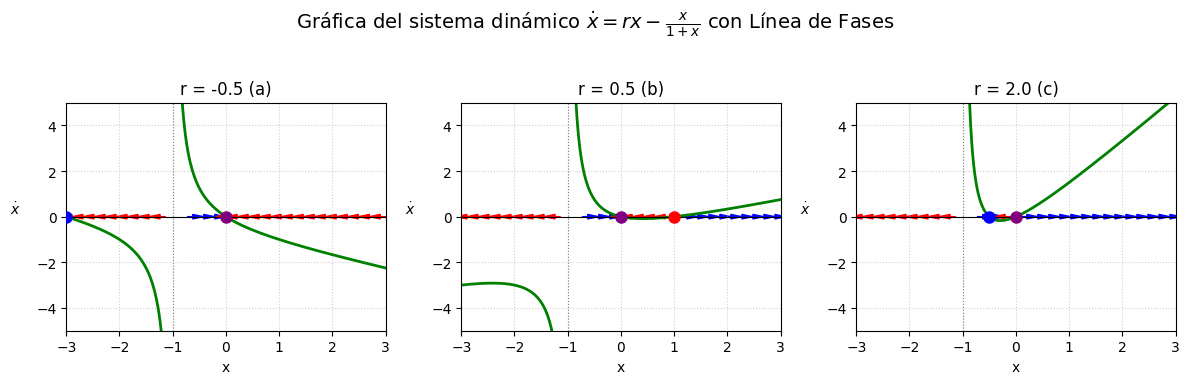

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    # La ecuación es: x_dot = r*x - x / (1 + x)
    # Para evitar división por cero en x=-1, lo manejamos con numpy's where
    return r * x - np.where(1 + x != 0, x / (1 + x), np.nan)

# --- Parámetros y rangos ---
# Los valores clave son: r=-0.5 (r < 0), r=0.5 (0 < r < 1), r=2.0 (r > 1)
r_vals_plot = [-0.5, 0.5, 2.0]
x_min, x_max = -3.0, 3.0
# Se debe tener cuidado alrededor de x = -1 (asíntota)
x_vals_left = np.linspace(x_min, -1.05, 200)
x_vals_right = np.linspace(-0.95, x_max, 200)

# Parámetros para las flechas de flujo
num_arrows = 15
arrow_length = 0.3

plt.figure(figsize=(12, 4))
plt.suptitle(r'Gráfica del sistema dinámico $\dot{x} = rx - \frac{x}{1+x}$ con Línea de Fases', fontsize=14)

for i, r in enumerate(r_vals_plot):
    plt.subplot(1, 3, i + 1)

    # 1. Calcular y graficar f(x) para la región izquierda (x < -1)
    f_vals_left = f(x_vals_left, r)
    plt.plot(x_vals_left, f_vals_left, color='green', linewidth=2)

    # 2. Calcular y graficar f(x) para la región derecha (x > -1)
    f_vals_right = f(x_vals_right, r)
    plt.plot(x_vals_right, f_vals_right, color='green', linewidth=2)

    # Dibujar la asíntota vertical en x=-1
    plt.axvline(-1.0, color='gray', linestyle=':', linewidth=0.8)

    # Línea del eje x (donde d(x)/dt = 0)
    plt.axhline(0, color='black', linewidth=0.8)

    # --- 3. Dibujar las flechas de la Línea de Fases (en el eje horizontal) ---

    # Puntos donde dibujaremos las flechas (evitando la asíntota x=-1)
    x_arrow_pos = np.linspace(x_min, x_max, 30)
    # Filtramos puntos demasiado cercanos a la asíntota
    x_arrow_pos = x_arrow_pos[np.abs(x_arrow_pos + 1.0) > 0.1]

    x_dot_at_arrows = f(x_arrow_pos, r)

    for x_pos, x_dot in zip(x_arrow_pos, x_dot_at_arrows):

        # Determinar si la flecha va a la derecha (positivo) o izquierda (negativo)
        if np.abs(x_dot) > 1e-3 and not np.isnan(x_dot):
            if x_dot > 0:
                direction = 1
                color = 'blue'
            else:
                direction = -1
                color = 'red'
        else: # Cerca de un punto fijo, no dibujar flecha grande
            direction = 0
            color = 'purple'

        if direction != 0:
            # Dibujar la flecha usando plt.arrow
            plt.arrow(
                x_pos, 0.0,                           # Coordenada inicial (x, y=0)
                direction * arrow_length, 0.0,        # Vector de cambio (dx, dy=0)
                head_width=0.2, head_length=0.2,      # Tamaño de la cabeza
                fc=color, ec=color, linewidth=1,      # Color de relleno y borde
                length_includes_head=True             # Incluir la cabeza en la longitud total
            )

    # --- 4. Marcar los Puntos Fijos ---
    # x* = 0 existe siempre.
    plt.plot(0, 0, 'o', color='purple', markersize=8, zorder=5)

    # x* = (1-r)/r existe si r != 0
    if r != 0 and r != 1:
        x_nontrivial = (1 - r) / r
        # Clasificamos estabilidad para colorear correctamente:
        # Si r > 1: x_nontrivial es estable (azul)
        # Si r < 1 y r > 0: x_nontrivial es inestable (rojo)
        # Si r < 0: x_nontrivial es estable (azul)

        if r > 1 or r < 0:
            color = 'blue'  # Estable
        else: # 0 < r < 1
            color = 'red'   # Inestable

        plt.plot(x_nontrivial, 0, 'o', color=color, markersize=8, zorder=5)

    # Etiquetas y título del subgráfico
    plt.title(f'r = {r} ({"a" if i==0 else "b" if i==1 else "c"})')
    plt.xlabel('x')
    plt.ylabel(r'$\dot{x}$', rotation=0, labelpad=15)
    plt.xlim(x_min, x_max)
    plt.ylim(-5, 5) # Ajustar límites Y para mejor visualización
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

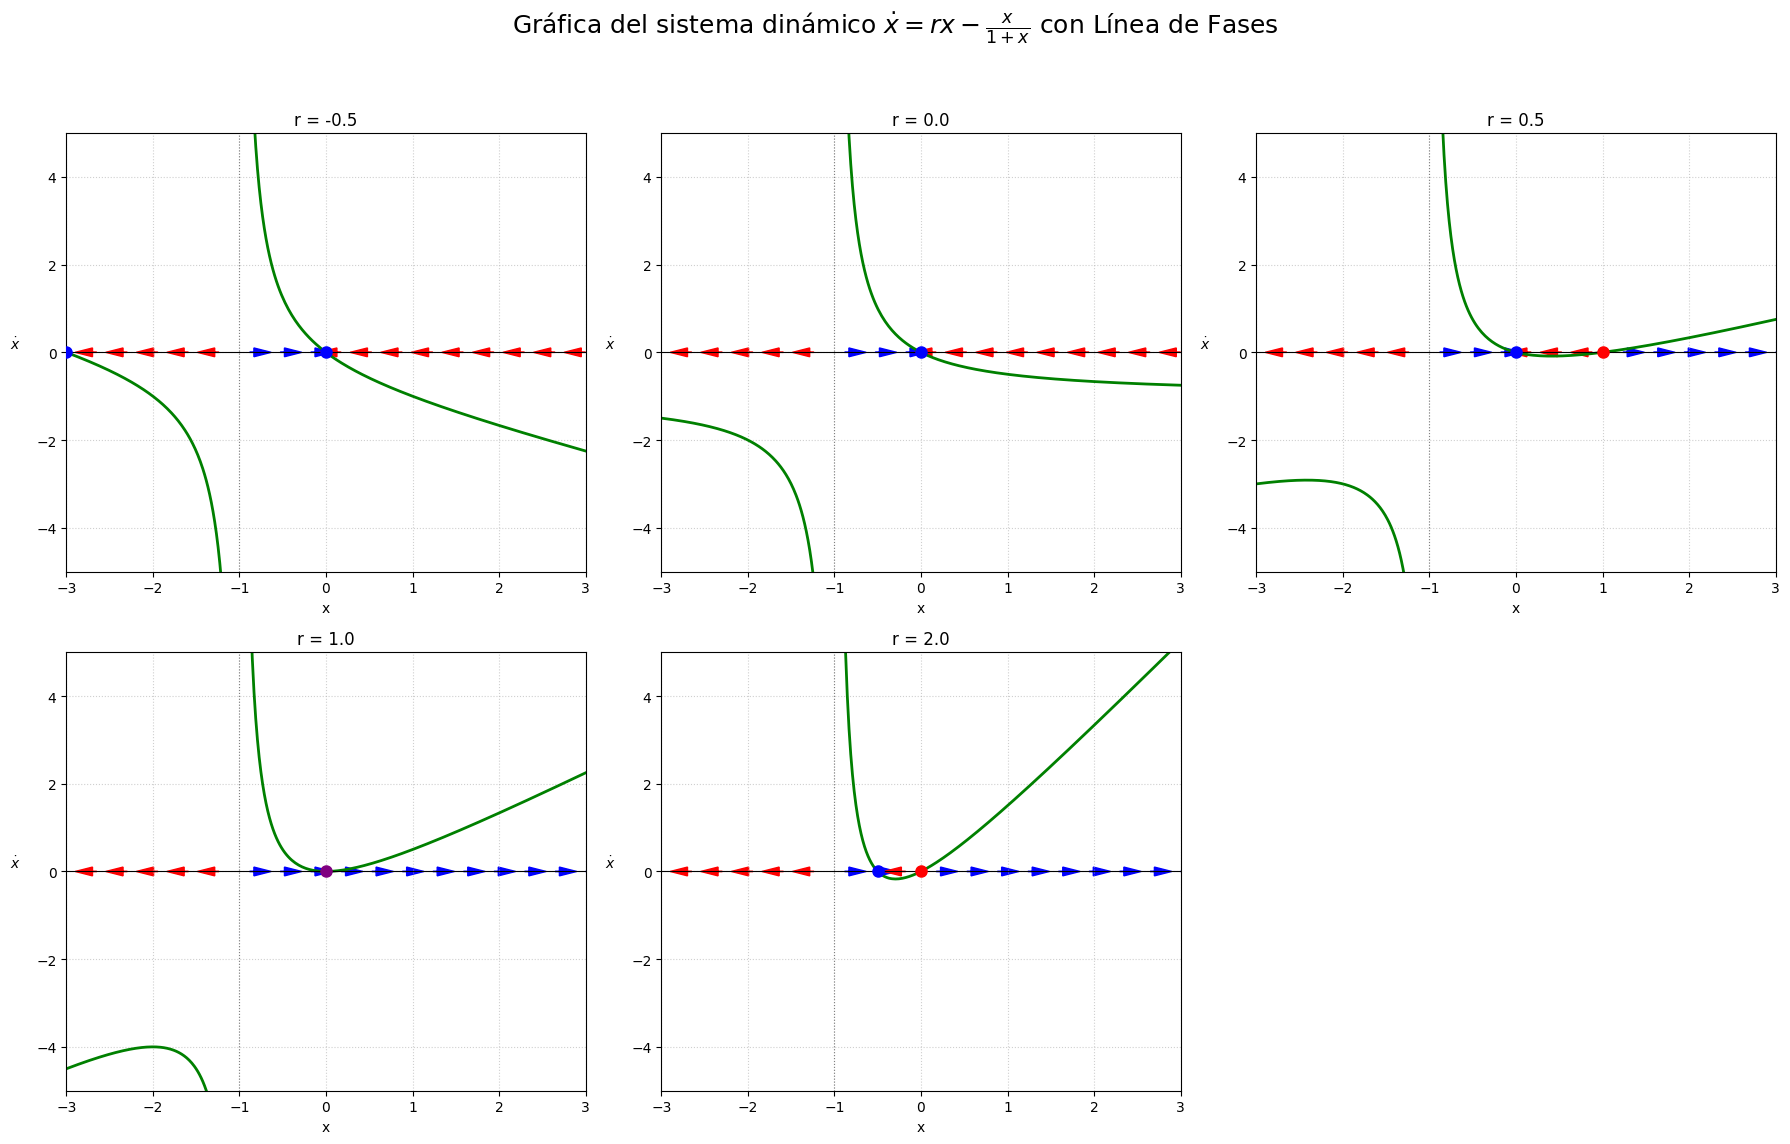

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    # La ecuación es: x_dot = r*x - x / (1 + x)
    # Usamos np.where para manejar la asíntota en x=-1, devolviendo NaN en ese punto.
    return r * x - np.where(np.abs(1 + x) > 1e-6, x / (1 + x), np.nan)

# --- Parámetros y rangos ---
# Valores clave de r: [-0.5, 0.0, 0.5, 1.0, 2.0]
r_vals_plot = [-0.5, 0.0, 0.5, 1.0, 2.0]
x_min, x_max = -3.0, 3.0
y_min, y_max = -5.0, 5.0

# Parámetros para las flechas de flujo
num_arrows = 18
arrow_length = 0.25

# Configuración de la figura para 5 subgráficos (2 filas, 3 columnas)
plt.figure(figsize=(18, 12))
plt.suptitle(r'Gráfica del sistema dinámico $\dot{x} = rx - \frac{x}{1+x}$ con Línea de Fases', fontsize=18)

for i, r in enumerate(r_vals_plot):
    # Crear el subgráfico en la posición correcta (2 filas, 3 columnas, índice i+1)
    plt.subplot(2, 3, i + 1)

    # 1. Definir los rangos de x, dividiendo alrededor de la asíntota en x=-1
    x_vals_left = np.linspace(x_min, -1.05, 200)
    x_vals_right = np.linspace(-0.95, x_max, 200)

    # Calcular y graficar f(x)
    f_vals_left = f(x_vals_left, r)
    f_vals_right = f(x_vals_right, r)

    plt.plot(x_vals_left, f_vals_left, color='green', linewidth=2)
    plt.plot(x_vals_right, f_vals_right, color='green', linewidth=2)

    # Línea del eje x (donde d(x)/dt = 0)
    plt.axhline(0, color='black', linewidth=0.8)
    # Asíntota vertical en x=-1
    plt.axvline(-1.0, color='gray', linestyle=':', linewidth=0.8)

    # --- 2. Dibujar las flechas de la Línea de Fases (en el eje horizontal) ---
    x_arrow_pos = np.linspace(x_min, x_max, num_arrows)
    x_arrow_pos = x_arrow_pos[np.abs(x_arrow_pos + 1.0) > 0.1] # Evitar la asíntota

    x_dot_at_arrows = f(x_arrow_pos, r)

    for x_pos, x_dot in zip(x_arrow_pos, x_dot_at_arrows):

        if np.abs(x_dot) > 1e-3 and not np.isnan(x_dot):
            if x_dot > 0:
                direction = 1
                color = 'blue'  # x aumenta (Estabilidad)
            else:
                direction = -1
                color = 'red'   # x disminuye (Inestabilidad)
        else:
            direction = 0

        if direction != 0:
            plt.arrow(
                x_pos, 0.0,
                direction * arrow_length, 0.0,
                head_width=0.2, head_length=0.2,
                fc=color, ec=color, linewidth=1,
                length_includes_head=True
            )

    # --- 3. Marcar los Puntos Fijos ---

    # x* = 0
    if r == 1.0:
        color_0 = 'purple' # No-hiperbólico en la bifurcación
    elif r < 1:
        color_0 = 'blue' # Estable si r < 1
    else:
        color_0 = 'red' # Inestable si r > 1

    plt.plot(0, 0, 'o', color=color_0, markersize=8, zorder=5)

    # x* = (1-r)/r (Punto no trivial)
    if r != 0 and r != 1:
        x_nontrivial = (1 - r) / r

        # Estabilidad: Estable si r > 1 o r < 0 (azul); Inestable si 0 < r < 1 (rojo).
        if (r > 0 and r < 1):
            color_nt = 'red'
        elif (r > 1) or (r < 0):
            color_nt = 'blue'

        if x_nontrivial >= x_min and x_nontrivial <= x_max:
             plt.plot(x_nontrivial, 0, 'o', color=color_nt, markersize=8, zorder=5)

    # Etiquetas y título del subgráfico
    plt.title(f'r = {r}')
    plt.xlabel('x')
    plt.ylabel(r'$\dot{x}$', rotation=0, labelpad=15)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

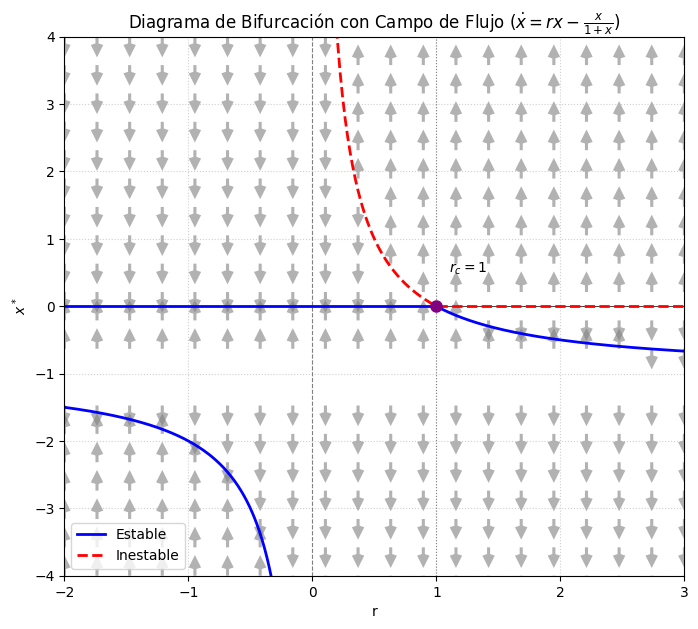

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    # La ecuación es: x_dot = r*x - x / (1 + x)
    # Devolver NaN cerca de la asíntota vertical x=-1 para evitar errores
    return r * x - np.where(np.abs(1 + x) > 1e-6, x / (1 + x), np.nan)

# --- Parámetros para el diagrama de bifurcación ---
r_min, r_max = -2.0, 3.0
x_min, x_max = -4.0, 4.0
r_c = 1.0 # Punto de bifurcación transcrítica

# Rango de r para los puntos fijos
r_vals = np.linspace(r_min, r_max, 500)
# Excluir r=0 para el cálculo de la rama no trivial y la gráfica
r_vals_plot = r_vals[np.abs(r_vals) > 0.001]

# --- Puntos Fijos ---
# 1. Rama Trivial: x* = 0
x_trivial = np.zeros_like(r_vals_plot)

# 2. Rama No Trivial: x* = (1-r)/r
x_nontrivial = (1 - r_vals_plot) / r_vals_plot

# --- Determinación de la Estabilidad para la Gráfica ---

# Rama Trivial (x*=0): Estable para r < 1 (Azul), Inestable para r > 1 (Rojo)
x_trivial_estable = np.where(r_vals_plot < r_c, x_trivial, np.nan)
x_trivial_inestable = np.where(r_vals_plot > r_c, x_trivial, np.nan)

# Rama No Trivial (x*=(1-r)/r): Estable si r>1 o r<0 (Azul), Inestable si 0 < r < 1 (Rojo)
# La estabilidad se invierte en r=0 (singularidad) y en r=1 (bifurcación)
# r > 1: Estable
# 0 < r < 1: Inestable
# r < 0: Estable
x_nontrivial_estable = np.where((r_vals_plot > r_c) | (r_vals_plot < 0.0), x_nontrivial, np.nan)
x_nontrivial_inestable = np.where((r_vals_plot > 0.0) & (r_vals_plot < r_c), x_nontrivial, np.nan)

# --- Configuración de la Gráfica ---
plt.figure(figsize=(8, 7))
plt.title(r'Diagrama de Bifurcación con Campo de Flujo ($\dot{x} = rx - \frac{x}{1+x}$)')
plt.xlabel('r')
plt.ylabel(r'$x^*$')
plt.axvline(r_c, color='gray', linestyle=':', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8) # Singularidad r=0
plt.axhline(0, color='black', linewidth=0.5)

# 1. Dibujar los puntos fijos (curvas)
plt.plot(r_vals_plot, x_trivial_estable, color='blue', linewidth=2, label='Estable')
plt.plot(r_vals_plot, x_trivial_inestable, color='red', linestyle='--', linewidth=2, label='Inestable')

plt.plot(r_vals_plot, x_nontrivial_estable, color='blue', linewidth=2)
plt.plot(r_vals_plot, x_nontrivial_inestable, color='red', linestyle='--', linewidth=2)

# Punto de Bifurcación (Transcrítica en r=1)
plt.plot(r_c, 0, 'o', color='purple', markersize=8, zorder=5)
plt.text(r_c + 0.1, 0.5, r'$r_c=1$', fontsize=10)


# --- 2. Cuadrícula para el campo de flechas (Quiver plot) ---
num_r_arrows = 20
num_x_arrows = 20
r_grid = np.linspace(r_min, r_max, num_r_arrows)
x_grid = np.linspace(x_min, x_max, num_x_arrows)
R_mesh, X_mesh = np.meshgrid(r_grid, x_grid)

# Componente U (flujo en r) siempre 0
U = np.zeros_like(R_mesh)
# Componente V (flujo en x) es la velocidad f(x,r)
V = f(X_mesh, R_mesh)

# Usamos el signo del flujo para la dirección (vertical)
V_sign = np.sign(V)
# Filtramos las flechas cerca de la asíntota x=-1 para que no se dibujen
V_sign = np.where(np.abs(X_mesh + 1.0) > 0.1, V_sign, np.nan)

# Dibujar las flechas
plt.quiver(R_mesh, X_mesh, U, V_sign,
           color='gray', alpha=0.6, scale=30, # Ajusta 'scale' para longitud
           width=0.005, headwidth=4, headlength=4, zorder=0)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left')
plt.xlim(r_min, r_max)
plt.ylim(x_min, x_max)
plt.show()

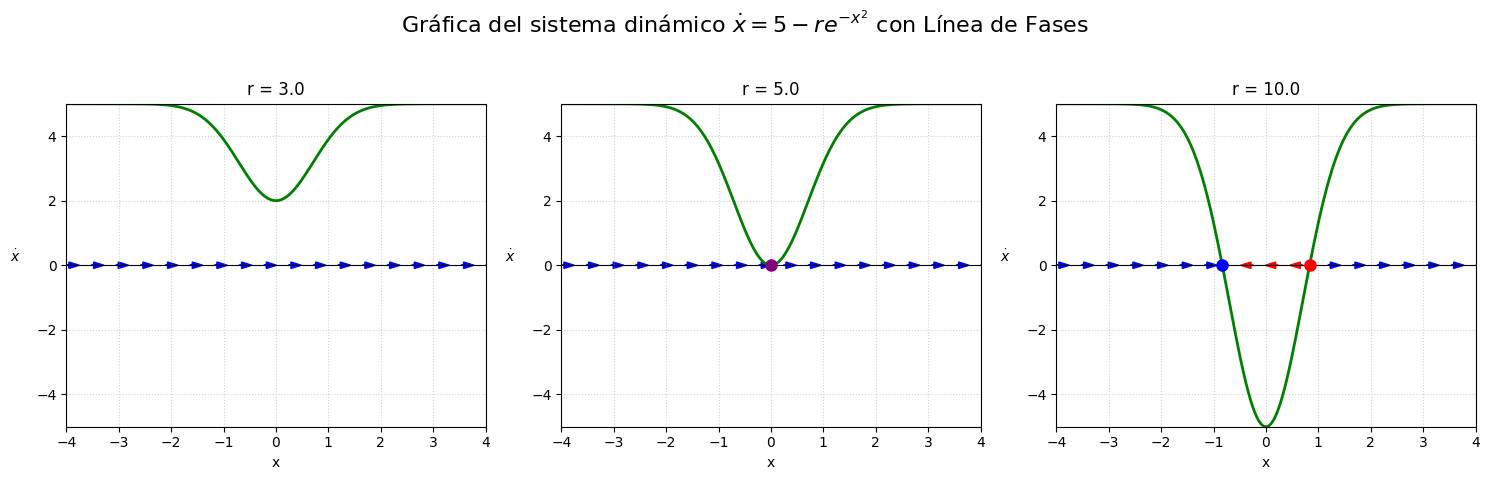

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    # Ecuación: x_dot = 5 - r * exp(-x^2)
    return 5 - r * np.exp(-x**2)

# --- Parámetros y rangos ---
r_vals_plot = [3.0, 5.0, 10.0]  # r < 5, r = 5, r > 5
x_min, x_max = -4.0, 4.0
y_min, y_max = -5.0, 5.0

# Parámetros para las flechas de flujo
num_arrows = 18
arrow_length = 0.25

plt.figure(figsize=(15, 5))
plt.suptitle(r'Gráfica del sistema dinámico $\dot{x} = 5 - r e^{-x^2}$ con Línea de Fases', fontsize=16)

for i, r in enumerate(r_vals_plot):
    plt.subplot(1, 3, i + 1)

    # 1. Calcular y graficar f(x)
    x_vals = np.linspace(x_min, x_max, 300)
    f_vals = f(x_vals, r)

    plt.plot(x_vals, f_vals, color='green', linewidth=2)
    plt.axhline(0, color='black', linewidth=0.8) # Eje x

    # --- 2. Dibujar las flechas de la Línea de Fases ---
    x_arrow_pos = np.linspace(x_min, x_max, num_arrows)
    x_dot_at_arrows = f(x_arrow_pos, r)

    for x_pos, x_dot in zip(x_arrow_pos, x_dot_at_arrows):

        # Flujo (flechas) solo donde la velocidad no es casi cero
        if np.abs(x_dot) > 0.1:
            if x_dot > 0:
                direction = 1
                color = 'blue'  # x aumenta (flujo positivo)
            else:
                direction = -1
                color = 'red'   # x disminuye (flujo negativo)
        else:
            direction = 0 # No dibujar flecha grande cerca del punto fijo

        if direction != 0:
            plt.arrow(
                x_pos, 0.0,
                direction * arrow_length, 0.0,
                head_width=0.2, head_length=0.2,
                fc=color, ec=color, linewidth=1,
                length_includes_head=True
            )

    # --- 3. Marcar los Puntos Fijos ---
    if r > 5:
        # x* = +/- sqrt(ln(r/5))
        x_star_abs = np.sqrt(np.log(r/5))

        # x*+ (inestable) y x*- (estable)
        plt.plot(x_star_abs, 0, 'o', color='red', markersize=8, zorder=5) # Inestable (derecha)
        plt.plot(-x_star_abs, 0, 'o', color='blue', markersize=8, zorder=5) # Estable (izquierda)
    elif r == 5:
        # x* = 0 (punto no-hiperbólico)
        plt.plot(0, 0, 'o', color='purple', markersize=8, zorder=5)

    # Etiquetas y título del subgráfico
    plt.title(f'r = {r}')
    plt.xlabel('x')
    plt.ylabel(r'$\dot{x}$', rotation=0, labelpad=15)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

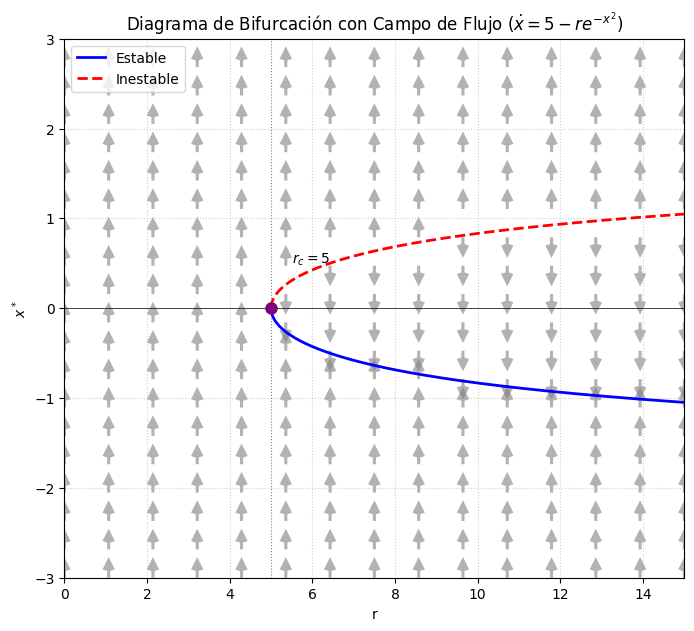

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    return 5 - r * np.exp(-x**2)

# --- Parámetros para el diagrama de bifurcación ---
r_min, r_max = 0.0, 15.0
x_min, x_max = -3.0, 3.0
r_c = 5.0 # Punto de bifurcación

# Rango de r para los puntos fijos
r_vals = np.linspace(r_c, r_max, 300)

# --- Puntos Fijos (solo existen para r >= 5) ---
x_star_abs = np.sqrt(np.log(r_vals/5.0))

# Rama Inestable (x* > 0)
x_inestable = x_star_abs

# Rama Estable (x* < 0)
x_estable = -x_star_abs

# --- Configuración de la Gráfica ---
plt.figure(figsize=(8, 7))
plt.title(r'Diagrama de Bifurcación con Campo de Flujo ($\dot{x} = 5 - r e^{-x^2}$)')
plt.xlabel('r')
plt.ylabel(r'$x^*$')
plt.axvline(r_c, color='gray', linestyle=':', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.5)

# 1. Dibujar los puntos fijos (curvas)
plt.plot(r_vals, x_estable, color='blue', linewidth=2, label='Estable')
plt.plot(r_vals, x_inestable, color='red', linestyle='--', linewidth=2, label='Inestable')

# Región r < 5 (no hay puntos fijos)
r_no_fp = np.linspace(r_min, r_c, 100)
plt.plot(r_no_fp, np.zeros_like(r_no_fp), color='none') # Solo para asegurar límites

# Punto de Bifurcación (Silla-Nodo en r=5, x=0)
plt.plot(r_c, 0, 'o', color='purple', markersize=8, zorder=5)
plt.text(r_c + 0.5, 0.5, r'$r_c=5$', fontsize=10)


# --- 2. Cuadrícula para el campo de flechas (Quiver plot) ---
num_r_arrows = 15
num_x_arrows = 20
r_grid = np.linspace(r_min, r_max, num_r_arrows)
x_grid = np.linspace(x_min, x_max, num_x_arrows)
R_mesh, X_mesh = np.meshgrid(r_grid, x_grid)

# Componente U (flujo en r) siempre 0
U = np.zeros_like(R_mesh)
# Componente V (flujo en x) es la velocidad f(x,r)
V = f(X_mesh, R_mesh)

# Usamos el signo del flujo para la dirección (vertical)
V_sign = np.sign(V)

# Dibujar las flechas
plt.quiver(R_mesh, X_mesh, U, V_sign,
           color='gray', alpha=0.6, scale=30,
           width=0.005, headwidth=4, headlength=4, zorder=0)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.xlim(r_min, r_max)
plt.ylim(x_min, x_max)
plt.show()

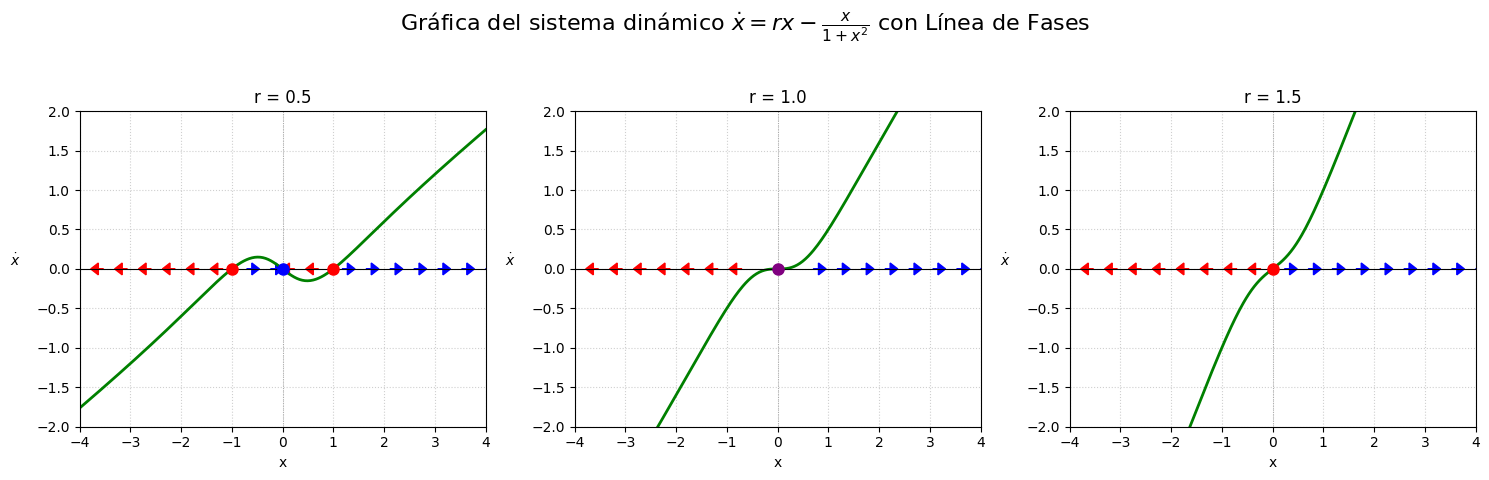

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    # Ecuación: x_dot = r*x - x / (1 + x^2)
    return r * x - x / (1 + x**2)

# --- Parámetros y rangos ---
r_vals_plot = [0.5, 1.0, 1.5]  # r < 1, r = 1, r > 1
x_min, x_max = -4.0, 4.0
y_min, y_max = -2.0, 2.0 # Ajustar límites Y para este sistema

# Parámetros para las flechas de flujo
num_arrows = 18
arrow_length = 0.25

plt.figure(figsize=(15, 5))
plt.suptitle(r'Gráfica del sistema dinámico $\dot{x} = r x - \frac{x}{1+x^2}$ con Línea de Fases', fontsize=16)

for i, r in enumerate(r_vals_plot):
    plt.subplot(1, 3, i + 1)

    # 1. Calcular y graficar f(x)
    x_vals = np.linspace(x_min, x_max, 300)
    f_vals = f(x_vals, r)

    plt.plot(x_vals, f_vals, color='green', linewidth=2)
    plt.axhline(0, color='black', linewidth=0.8) # Eje x
    plt.axvline(0, color='gray', linestyle=':', linewidth=0.5) # Eje y (para referencia)

    # --- 2. Dibujar las flechas de la Línea de Fases ---
    x_arrow_pos = np.linspace(x_min, x_max, num_arrows)
    x_dot_at_arrows = f(x_arrow_pos, r)

    for x_pos, x_dot in zip(x_arrow_pos, x_dot_at_arrows):

        # Flujo (flechas) solo donde la velocidad no es casi cero
        if np.abs(x_dot) > 0.05: # Umbral más bajo para este sistema
            if x_dot > 0:
                direction = 1
                color = 'blue'  # x aumenta (flujo positivo)
            else:
                direction = -1
                color = 'red'   # x disminuye (flujo negativo)
        else:
            direction = 0

        if direction != 0:
            plt.arrow(
                x_pos, 0.0,
                direction * arrow_length, 0.0,
                head_width=0.15, head_length=0.15, # Flechas más pequeñas
                fc=color, ec=color, linewidth=1,
                length_includes_head=True
            )

    # --- 3. Marcar los Puntos Fijos ---
    # x* = 0 siempre es un punto fijo.
    # Color según estabilidad: azul (estable) si r < 1, rojo (inestable) si r > 1, morado (bif.) si r = 1
    if r < 1: color_0 = 'blue'
    elif r > 1: color_0 = 'red'
    else: color_0 = 'purple'
    plt.plot(0, 0, 'o', color=color_0, markersize=8, zorder=5)

    # Puntos fijos no triviales: x* = +/- sqrt(1/r - 1)
    if 0 < r < 1:
        x_star_abs = np.sqrt(1/r - 1)
        # Estos puntos son inestables (rojo)
        plt.plot(x_star_abs, 0, 'o', color='red', markersize=8, zorder=5)
        plt.plot(-x_star_abs, 0, 'o', color='red', markersize=8, zorder=5)

    # Etiquetas y título del subgráfico
    plt.title(f'r = {r}')
    plt.xlabel('x')
    plt.ylabel(r'$\dot{x}$', rotation=0, labelpad=15)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

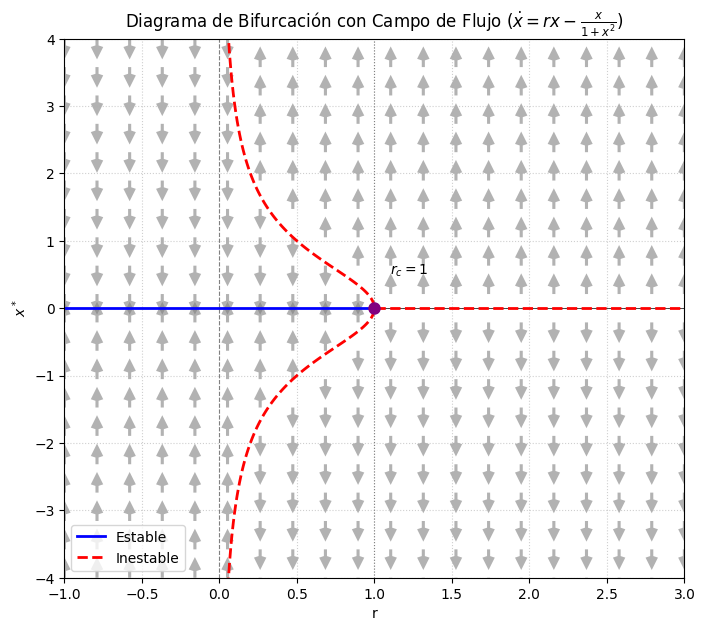

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    return r * x - x / (1 + x**2)

# --- Parámetros para el diagrama de bifurcación ---
r_min, r_max = -1.0, 3.0
x_min, x_max = -4.0, 4.0
r_c = 1.0 # Punto de bifurcación

# Rango de r para los puntos fijos
r_vals = np.linspace(r_min, r_max, 500)

# --- Puntos Fijos ---
# 1. Rama Trivial: x* = 0
x_trivial = np.zeros_like(r_vals)

# 2. Ramas No Triviales: x* = +/- sqrt(1/r - 1)
# Solo existen para 0 < r <= 1
r_nontrivial_range = r_vals[(r_vals > 0.0) & (r_vals <= 1.0)]
x_nontrivial_abs = np.sqrt(1 / r_nontrivial_range - 1)

# --- Determinación de la Estabilidad para la Gráfica ---

# x*=0: Estable para r < 1 (Azul), Inestable para r > 1 (Rojo)
x_trivial_estable = np.where(r_vals < r_c, x_trivial, np.nan)
x_trivial_inestable = np.where(r_vals > r_c, x_trivial, np.nan)

# x*= +/- sqrt(1/r - 1): Siempre inestables para 0 < r < 1 (Rojo)
x_nontrivial_inestable_pos = x_nontrivial_abs
x_nontrivial_inestable_neg = -x_nontrivial_abs


# --- Configuración de la Gráfica ---
plt.figure(figsize=(8, 7))
plt.title(r'Diagrama de Bifurcación con Campo de Flujo ($\dot{x} = r x - \frac{x}{1+x^2}$)')
plt.xlabel('r')
plt.ylabel(r'$x^*$')
plt.axvline(r_c, color='gray', linestyle=':', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8) # Referencia para r=0
plt.axhline(0, color='black', linewidth=0.5)

# 1. Dibujar los puntos fijos (curvas)
plt.plot(r_vals, x_trivial_estable, color='blue', linewidth=2, label='Estable')
plt.plot(r_vals, x_trivial_inestable, color='red', linestyle='--', linewidth=2, label='Inestable')

plt.plot(r_nontrivial_range, x_nontrivial_inestable_pos, color='red', linestyle='--', linewidth=2)
plt.plot(r_nontrivial_range, x_nontrivial_inestable_neg, color='red', linestyle='--', linewidth=2)


# Punto de Bifurcación (Horquilla Supercrítica en r=1, x=0)
plt.plot(r_c, 0, 'o', color='purple', markersize=8, zorder=5)
plt.text(r_c + 0.1, 0.5, r'$r_c=1$', fontsize=10)


# --- 2. Cuadrícula para el campo de flechas (Quiver plot) ---
num_r_arrows = 20
num_x_arrows = 20
r_grid = np.linspace(r_min, r_max, num_r_arrows)
x_grid = np.linspace(x_min, x_max, num_x_arrows)
R_mesh, X_mesh = np.meshgrid(r_grid, x_grid)

# Componente U (flujo en r) siempre 0
U = np.zeros_like(R_mesh)
# Componente V (flujo en x) es la velocidad f(x,r)
V = f(X_mesh, R_mesh)

# Usamos el signo del flujo para la dirección (vertical)
V_sign = np.sign(V)

# Dibujar las flechas
plt.quiver(R_mesh, X_mesh, U, V_sign,
           color='gray', alpha=0.6, scale=30,
           width=0.005, headwidth=4, headlength=4, zorder=0)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left')
plt.xlim(r_min, r_max)
plt.ylim(x_min, x_max)
plt.show()

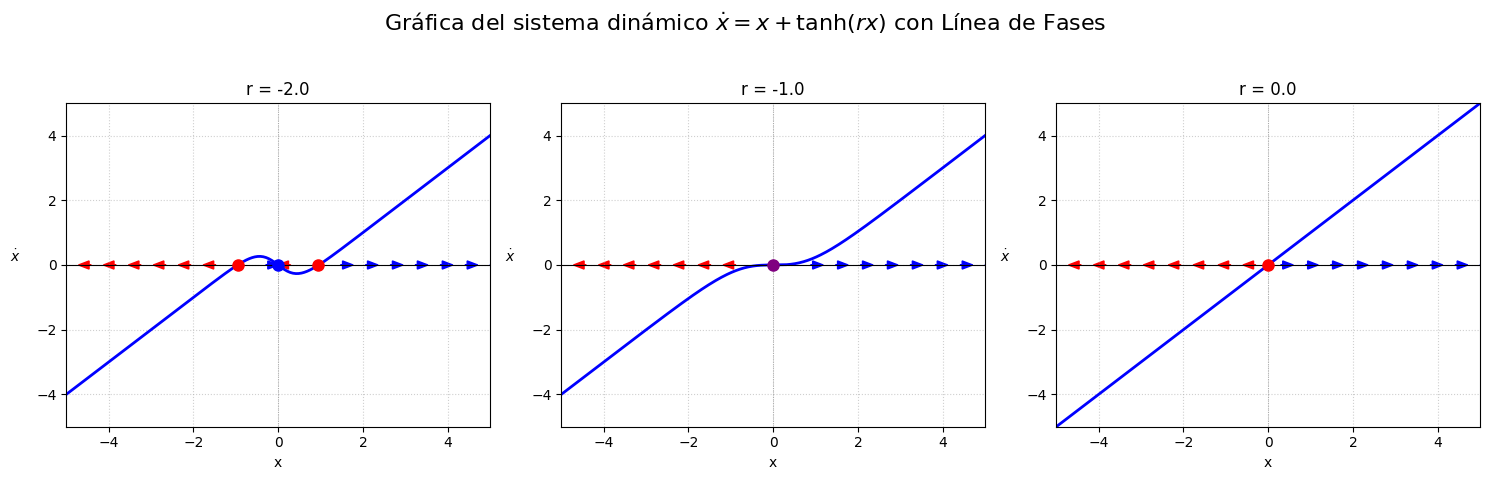

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    # Ecuación: x_dot = x + tanh(r*x)
    return x + np.tanh(r * x)

# --- Parámetros y rangos ---
r_vals_plot = [-2.0, -1.0, 0.0]  # r < -1, r = -1, r > -1
x_min, x_max = -5.0, 5.0
y_min, y_max = -5.0, 5.0

# Parámetros para las flechas de flujo
num_arrows = 18
arrow_length = 0.3

plt.figure(figsize=(15, 5))
plt.suptitle(r'Gráfica del sistema dinámico $\dot{x} = x + \tanh(rx)$ con Línea de Fases', fontsize=16)

for i, r in enumerate(r_vals_plot):
    plt.subplot(1, 3, i + 1)

    # 1. Calcular y graficar f(x)
    x_vals = np.linspace(x_min, x_max, 300)
    f_vals = f(x_vals, r)

    plt.plot(x_vals, f_vals, color='blue', linewidth=2)
    plt.axhline(0, color='black', linewidth=0.8) # Eje x
    plt.axvline(0, color='gray', linestyle=':', linewidth=0.5) # Eje y

    # --- 2. Dibujar las flechas de la Línea de Fases ---
    x_arrow_pos = np.linspace(x_min, x_max, num_arrows)
    x_dot_at_arrows = f(x_arrow_pos, r)

    for x_pos, x_dot in zip(x_arrow_pos, x_dot_at_arrows):

        # Clasificación del flujo
        if np.abs(x_dot) > 0.1:
            if x_dot > 0:
                direction = 1
                color = 'blue'  # x aumenta
            else:
                direction = -1
                color = 'red'   # x disminuye
        else:
            direction = 0

        if direction != 0:
            plt.arrow(
                x_pos, 0.0,
                direction * arrow_length, 0.0,
                head_width=0.25, head_length=0.25,
                fc=color, ec=color, linewidth=1,
                length_includes_head=True
            )

    # --- 3. Marcar los Puntos Fijos ---

    # x* = 0
    if r < -1: color_0 = 'blue'
    elif r > -1: color_0 = 'red'
    else: color_0 = 'purple'
    plt.plot(0, 0, 'o', color=color_0, markersize=8, zorder=5)

    # Puntos fijos no triviales (x* = -tanh(r*x*)) - solo existen para r < -1
    if r < -1:
        # Resolvemos numéricamente (aproximación visual)
        # Buscar raíces cerca de los cruces de x y -tanh(r*x)
        # Para r = -2, las raíces son aproximadamente x* = +/- 0.95
        if r == -2.0:
            x_star_abs = 0.95
            # Estos puntos son inestables (rojo)
            plt.plot(x_star_abs, 0, 'o', color='red', markersize=8, zorder=5)
            plt.plot(-x_star_abs, 0, 'o', color='red', markersize=8, zorder=5)

    # Etiquetas y título del subgráfico
    plt.title(f'r = {r}')
    plt.xlabel('x')
    plt.ylabel(r'$\dot{x}$', rotation=0, labelpad=15)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

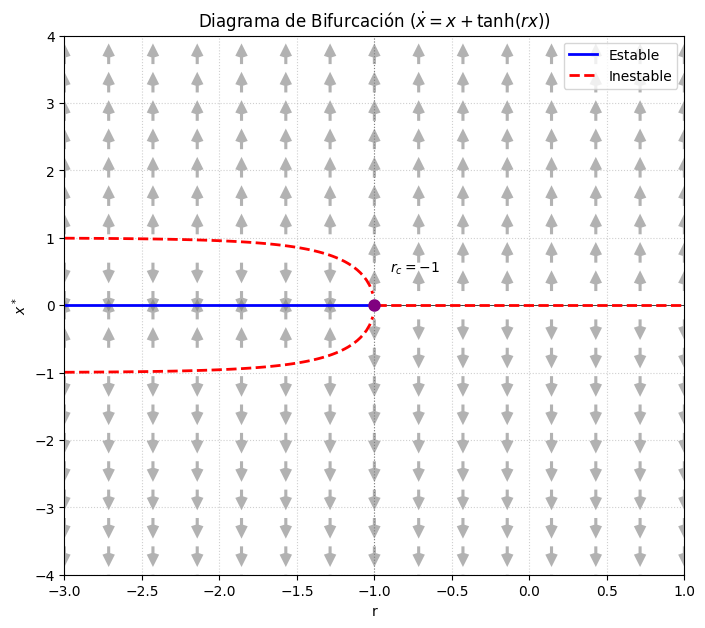

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

# --- Definición de la función del campo vectorial ---
def f(x, r):
    return x + np.tanh(r * x)

# Función para encontrar puntos fijos no triviales: x + tanh(r*x) = 0
def fixed_point_equation(x, r):
    return f(x, r)

# --- Parámetros para el diagrama de bifurcación ---
r_min, r_max = -3.0, 1.0
x_min, x_max = -4.0, 4.0
r_c = -1.0 # Punto de bifurcación

# Rango de r para los puntos fijos
r_vals = np.linspace(r_min, r_max, 200)

# --- Puntos Fijos ---
# 1. Rama Trivial: x* = 0 (Estable para r < -1, Inestable para r > -1)
x_trivial = np.zeros_like(r_vals)
x_trivial_estable = np.where(r_vals < r_c, x_trivial, np.nan)
x_trivial_inestable = np.where(r_vals > r_c, x_trivial, np.nan)

# 2. Ramas No Triviales (solo existen para r < -1)
r_nontrivial_range = r_vals[r_vals < r_c]

x_nontrivial_pos = []
x_nontrivial_neg = []

# Encontrar raíces numéricamente
for r_val in r_nontrivial_range:
    # Usar una estimación cercana a 1.0 como punto de partida
    try:
        root_pos = fsolve(fixed_point_equation, 1.0, args=(r_val,))[0]
        x_nontrivial_pos.append(root_pos)
    except:
        x_nontrivial_pos.append(np.nan)

    # Usar una estimación cercana a -1.0 como punto de partida
    try:
        root_neg = fsolve(fixed_point_equation, -1.0, args=(r_val,))[0]
        x_nontrivial_neg.append(root_neg)
    except:
        x_nontrivial_neg.append(np.nan)

# Estas ramas son inestables (rojo discontinuo)
x_nontrivial_inestable_pos = np.array(x_nontrivial_pos)
x_nontrivial_inestable_neg = np.array(x_nontrivial_neg)


# --- Configuración de la Gráfica ---
plt.figure(figsize=(8, 7))
plt.title(r'Diagrama de Bifurcación ($\dot{x} = x + \tanh(rx)$)')
plt.xlabel('r')
plt.ylabel(r'$x^*$')
plt.axvline(r_c, color='gray', linestyle=':', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.5)

# 1. Dibujar los puntos fijos (curvas)
plt.plot(r_vals, x_trivial_estable, color='blue', linewidth=2, label='Estable')
plt.plot(r_vals, x_trivial_inestable, color='red', linestyle='--', linewidth=2, label='Inestable')

plt.plot(r_nontrivial_range, x_nontrivial_inestable_pos, color='red', linestyle='--', linewidth=2)
plt.plot(r_nontrivial_range, x_nontrivial_inestable_neg, color='red', linestyle='--', linewidth=2)


# Punto de Bifurcación (Horquilla Subcrítica en r=-1, x=0)
plt.plot(r_c, 0, 'o', color='purple', markersize=8, zorder=5)
plt.text(r_c + 0.1, 0.5, r'$r_c=-1$', fontsize=10)


# --- 2. Cuadrícula para el campo de flechas (Quiver plot) ---
num_r_arrows = 15
num_x_arrows = 20
r_grid = np.linspace(r_min, r_max, num_r_arrows)
x_grid = np.linspace(x_min, x_max, num_x_arrows)
R_mesh, X_mesh = np.meshgrid(r_grid, x_grid)

# Componente U (flujo en r) siempre 0
U = np.zeros_like(R_mesh)
# Componente V (flujo en x) es la velocidad f(x,r)
V = f(X_mesh, R_mesh)

# Usamos el signo del flujo para la dirección (vertical)
V_sign = np.sign(V)

# Dibujar las flechas
plt.quiver(R_mesh, X_mesh, U, V_sign,
           color='gray', alpha=0.6, scale=30,
           width=0.005, headwidth=4, headlength=4, zorder=0)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.xlim(r_min, r_max)
plt.ylim(x_min, x_max)
plt.show()

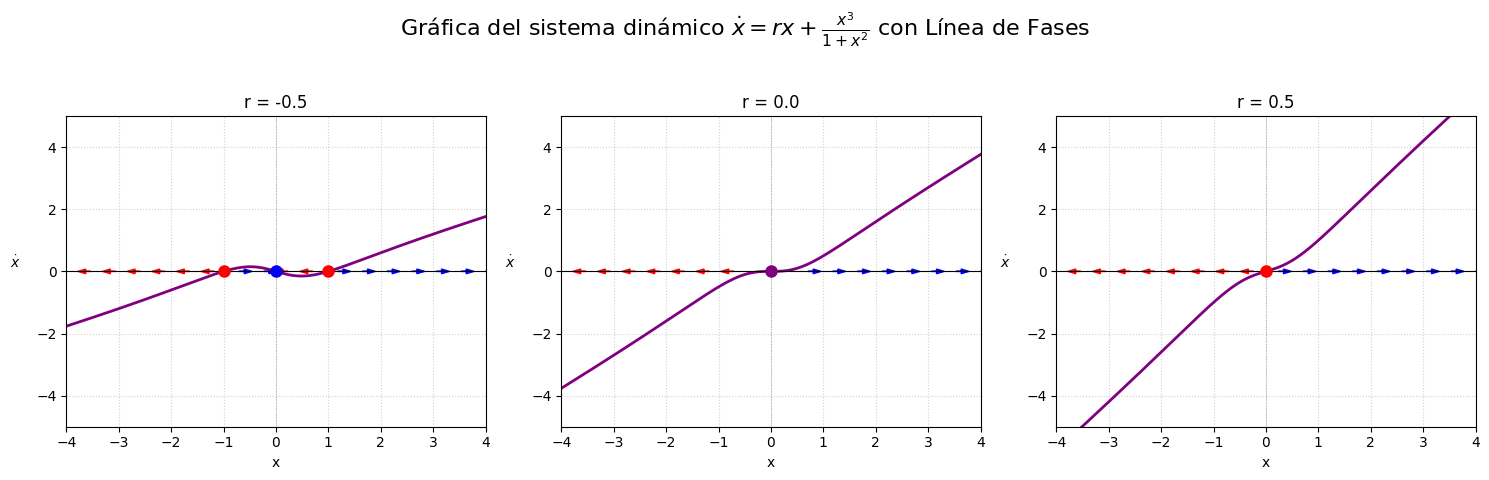

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    # Ecuación: x_dot = r*x + x^3 / (1 + x^2)
    return r * x + (x**3) / (1 + x**2)

# --- Parámetros y rangos ---
r_vals_plot = [-0.5, 0.0, 0.5]  # r < 0, r = 0, r > 0
x_min, x_max = -4.0, 4.0
y_min, y_max = -5.0, 5.0

# Parámetros para las flechas de flujo
num_arrows = 18
arrow_length = 0.25

plt.figure(figsize=(15, 5))
plt.suptitle(r'Gráfica del sistema dinámico $\dot{x} = r x + \frac{x^3}{1+x^2}$ con Línea de Fases', fontsize=16)

for i, r in enumerate(r_vals_plot):
    plt.subplot(1, 3, i + 1)

    # 1. Calcular y graficar f(x)
    x_vals = np.linspace(x_min, x_max, 300)
    f_vals = f(x_vals, r)

    plt.plot(x_vals, f_vals, color='purple', linewidth=2)
    plt.axhline(0, color='black', linewidth=0.8) # Eje x
    plt.axvline(0, color='gray', linestyle=':', linewidth=0.5) # Eje y

    # --- 2. Dibujar las flechas de la Línea de Fases ---
    x_arrow_pos = np.linspace(x_min, x_max, num_arrows)
    x_dot_at_arrows = f(x_arrow_pos, r)

    for x_pos, x_dot in zip(x_arrow_pos, x_dot_at_arrows):

        if np.abs(x_dot) > 0.05:
            if x_dot > 0:
                direction = 1
                color = 'blue'  # x aumenta
            else:
                direction = -1
                color = 'red'   # x disminuye
        else:
            direction = 0

        if direction != 0:
            plt.arrow(
                x_pos, 0.0,
                direction * arrow_length, 0.0,
                head_width=0.15, head_length=0.15,
                fc=color, ec=color, linewidth=1,
                length_includes_head=True
            )

    # --- 3. Marcar los Puntos Fijos ---

    # x* = 0
    if r < 0: color_0 = 'blue'
    elif r > 0: color_0 = 'red'
    else: color_0 = 'purple'
    plt.plot(0, 0, 'o', color=color_0, markersize=8, zorder=5)

    # Puntos fijos no triviales: x* = +/- sqrt(-r / (1+r))
    if -1 < r < 0:
        x_star_abs = np.sqrt(-r / (1 + r))
        # Estos puntos son inestables (rojo)
        plt.plot(x_star_abs, 0, 'o', color='red', markersize=8, zorder=5)
        plt.plot(-x_star_abs, 0, 'o', color='red', markersize=8, zorder=5)

    # Etiquetas y título del subgráfico
    plt.title(f'r = {r}')
    plt.xlabel('x')
    plt.ylabel(r'$\dot{x}$', rotation=0, labelpad=15)
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

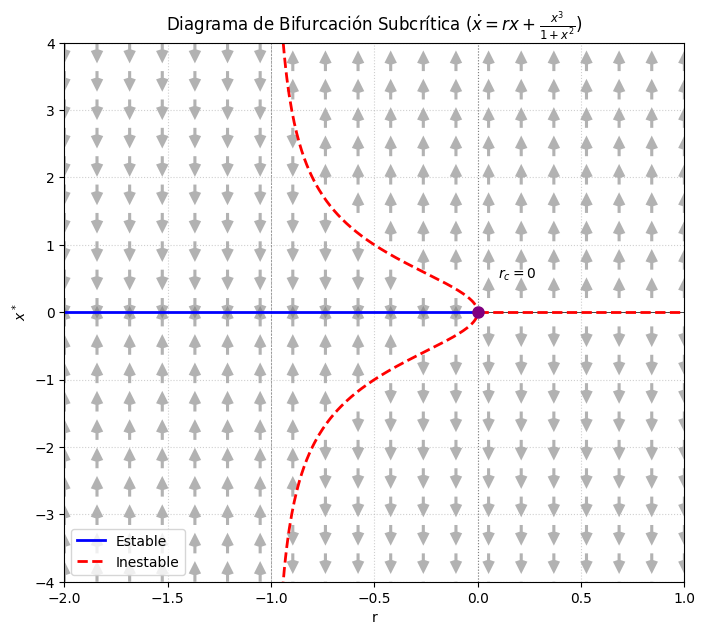

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Definición de la función del campo vectorial ---
def f(x, r):
    return r * x + (x**3) / (1 + x**2)

# --- Parámetros para el diagrama de bifurcación ---
r_min, r_max = -2.0, 1.0
x_min, x_max = -4.0, 4.0
r_c = 0.0 # Punto de bifurcación

# Rango de r para los puntos fijos
r_vals = np.linspace(r_min, r_max, 500)

# --- Puntos Fijos ---
# 1. Rama Trivial: x* = 0
x_trivial = np.zeros_like(r_vals)

# Estabilidad de x*=0: Estable para r < 0 (Azul), Inestable para r > 0 (Rojo)
x_trivial_estable = np.where(r_vals < r_c, x_trivial, np.nan)
x_trivial_inestable = np.where(r_vals > r_c, x_trivial, np.nan)

# 2. Ramas No Triviales (solo existen para -1 < r <= 0)
r_nontrivial_range = r_vals[(r_vals > -1.0) & (r_vals <= 0.0)]
x_nontrivial_abs = np.sqrt(-r_nontrivial_range / (1 + r_nontrivial_range))

# Estas ramas son inestables (rojo discontinuo)
x_nontrivial_inestable_pos = x_nontrivial_abs
x_nontrivial_inestable_neg = -x_nontrivial_abs


# --- Configuración de la Gráfica ---
plt.figure(figsize=(8, 7))
plt.title(r'Diagrama de Bifurcación Subcrítica ($\dot{x} = r x + \frac{x^3}{1+x^2}$)')
plt.xlabel('r')
plt.ylabel(r'$x^*$')
plt.axvline(r_c, color='gray', linestyle=':', linewidth=0.8)
plt.axvline(-1.0, color='gray', linestyle='--', linewidth=0.5) # Asymptote/límite
plt.axhline(0, color='black', linewidth=0.5)

# 1. Dibujar los puntos fijos (curvas)
plt.plot(r_vals, x_trivial_estable, color='blue', linewidth=2, label='Estable')
plt.plot(r_vals, x_trivial_inestable, color='red', linestyle='--', linewidth=2, label='Inestable')

plt.plot(r_nontrivial_range, x_nontrivial_inestable_pos, color='red', linestyle='--', linewidth=2)
plt.plot(r_nontrivial_range, x_nontrivial_inestable_neg, color='red', linestyle='--', linewidth=2)


# Punto de Bifurcación (Horquilla Subcrítica en r=0, x=0)
plt.plot(r_c, 0, 'o', color='purple', markersize=8, zorder=5)
plt.text(r_c + 0.1, 0.5, r'$r_c=0$', fontsize=10)


# --- 2. Cuadrícula para el campo de flechas (Quiver plot) ---
num_r_arrows = 20
num_x_arrows = 20
r_grid = np.linspace(r_min, r_max, num_r_arrows)
x_grid = np.linspace(x_min, x_max, num_x_arrows)
R_mesh, X_mesh = np.meshgrid(r_grid, x_grid)

# Componente U (flujo en r) siempre 0
U = np.zeros_like(R_mesh)
# Componente V (flujo en x) es la velocidad f(x,r)
V = f(X_mesh, R_mesh)

# Usamos el signo del flujo para la dirección (vertical)
V_sign = np.sign(V)

# Dibujar las flechas
plt.quiver(R_mesh, X_mesh, U, V_sign,
           color='gray', alpha=0.6, scale=30,
           width=0.005, headwidth=4, headlength=4, zorder=0)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left')
plt.xlim(r_min, r_max)
plt.ylim(x_min, x_max)
plt.show()

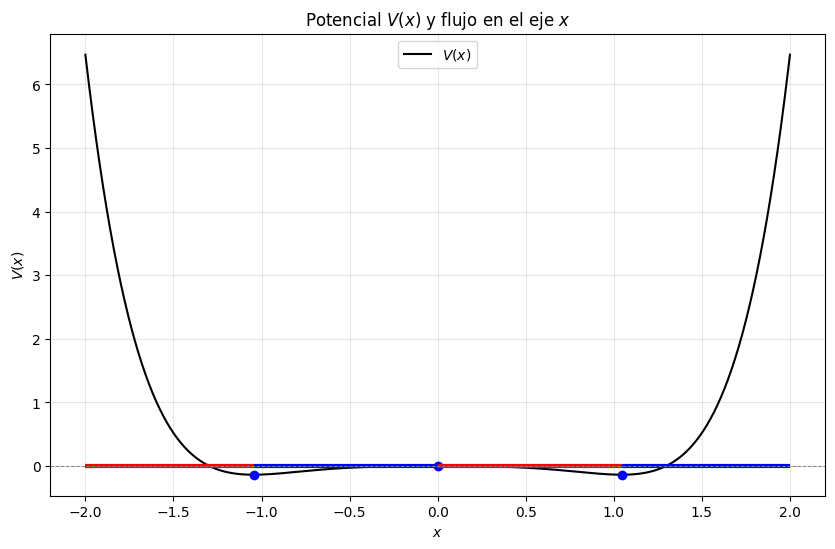

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, solve

# Parámetro
r = 0.1  # puedes cambiar este valor

# Definición del sistema
def f(x, r):
    return r*x + x**3 - x**5

# Potencial V(x): V'(x) = -f(x) => V(x) = -∫ f(x) dx
def V(x, r):
    return -(r*x**2/2 + x**4/4 - x**6/6)

# Rango de x
x = np.linspace(-2, 2, 400)
y = V(x, r)

# Puntos críticos (raíces de f(x)=0)
X = symbols('X')
roots = solve(r*X + X**3 - X**5, X)
roots = sorted([float(root.evalf()) for root in roots if abs(root.as_real_imag()[1]) < 1e-6])

# Graficamos el potencial
plt.figure(figsize=(10,6))
plt.plot(x, y, 'k', label='$V(x)$')

# Marcar puntos críticos
for root in roots:
    plt.plot(root, V(root, r), 'bo')

# Dibujar líneas horizontales en el eje x
for i in range(len(roots)-1):
    mid = (roots[i] + roots[i+1]) / 2
    if f(mid, r) > 0:  # flujo hacia la derecha
        plt.hlines(0, roots[i], roots[i+1], colors='red', linewidth=3)
    else:  # flujo hacia la izquierda
        plt.hlines(0, roots[i], roots[i+1], colors='blue', linewidth=3)

# Extremos fuera de los puntos críticos
if f(roots[0]-1, r) > 0:
    plt.hlines(0, -2, roots[0], colors='red', linewidth=3)
else:
    plt.hlines(0, -2, roots[0], colors='blue', linewidth=3)

if f(roots[-1]+1, r) > 0:
    plt.hlines(0, roots[-1], 2, colors='red', linewidth=3)
else:
    plt.hlines(0, roots[-1], 2, colors='blue', linewidth=3)

# Ajustes
plt.title("Potencial $V(x)$ y flujo en el eje $x$")
plt.xlabel("$x$")
plt.ylabel("$V(x)$")
plt.axhline(0, color="gray", linestyle="--", linewidth=0.7)
plt.legend()
plt.grid(alpha=0.3)
plt.show()




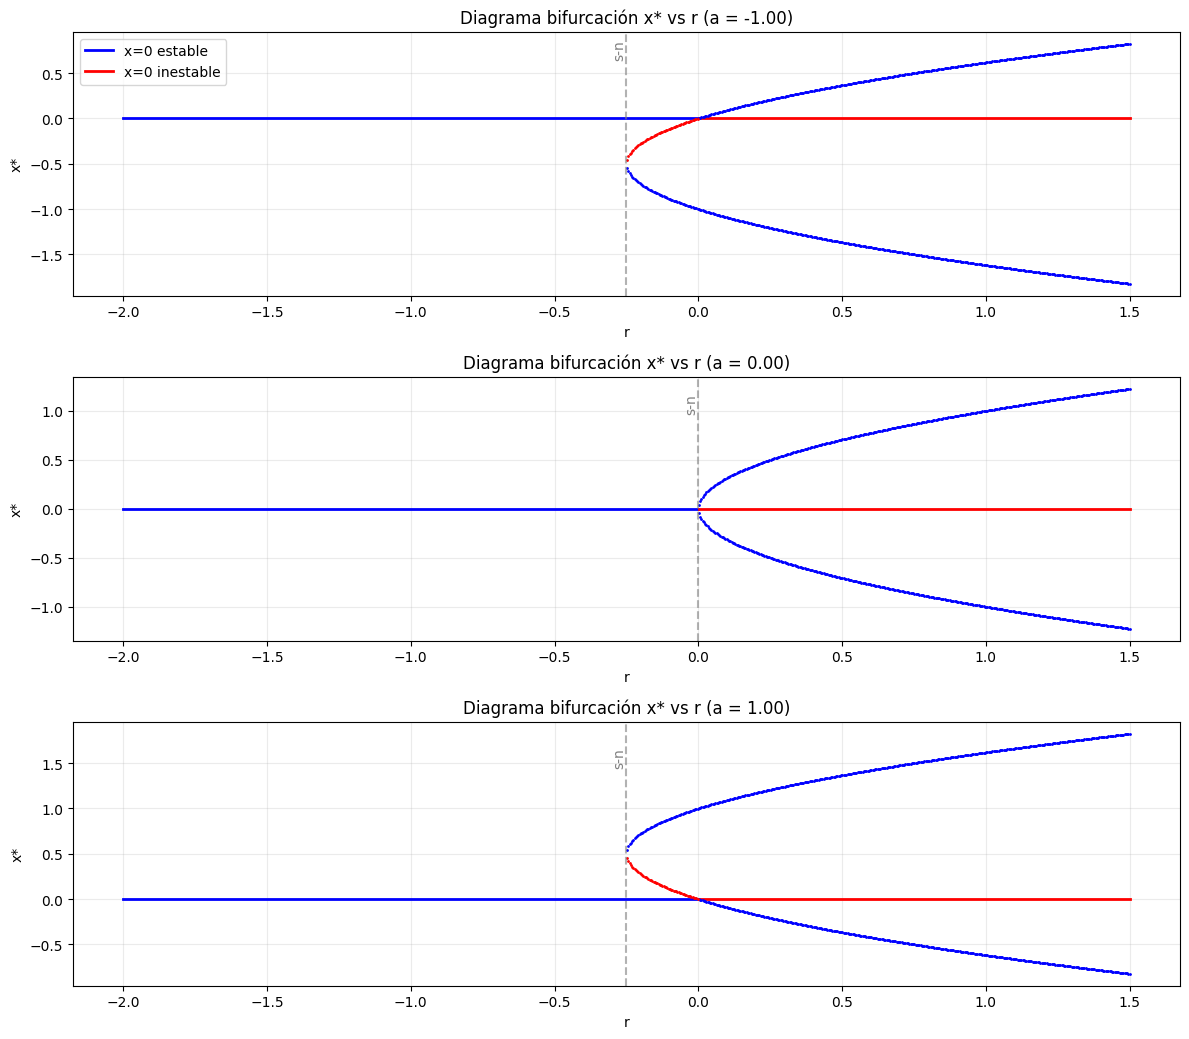

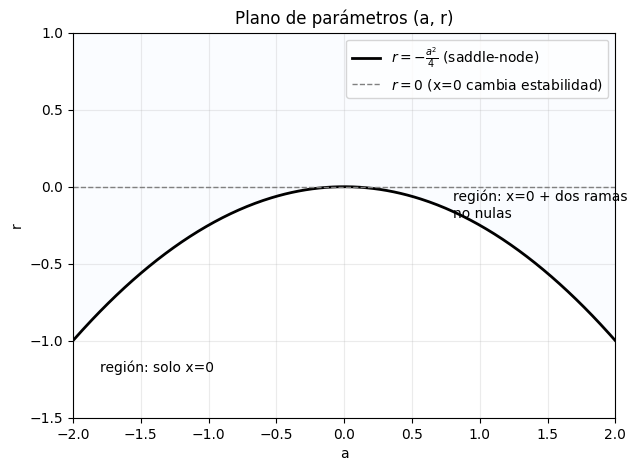

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Sistema: x' = r x + a x^2 - x^3
# Equilibria: x = 0  and roots of -x^2 + a x + r = 0
# i.e. x = (a ± sqrt(a^2 + 4 r))/2  (when discriminant >= 0)

def equilibria_nonzero(a, r):
    """Return nonzero equilibria (real) for given a,r (as numpy array)."""
    disc = a*a + 4.0*r
    if disc < 0:
        return np.array([])  # no real nonzero equilibria
    s = np.sqrt(disc)
    x1 = 0.5*(a + s)
    x2 = 0.5*(a - s)
    # order them for plotting (largest first)
    return np.array(sorted([x1, x2]))

def fprime(x, a, r):
    """Derivative f'(x) = r + 2 a x - 3 x^2"""
    return r + 2.0*a*x - 3.0*x*x

# --- Part 1: bifurcation diagrams x* vs r for several a ---
a_list = [-1.0, 0.0, 1.0]    # cambia o añade elementos si quieres más casos
r_vals = np.linspace(-2.0, 1.5, 800)

plt.figure(figsize=(12,3.5*len(a_list)))
for i,a in enumerate(a_list, start=1):
    ax = plt.subplot(len(a_list),1,i)
    # plot x=0 branch and its stability
    x0_stability = [ ('stable' if r<0 else 'unstable') for r in r_vals ]
    # draw x=0 (stable region blue, unstable red)
    ax.plot(r_vals, np.zeros_like(r_vals), color='k', lw=0.8)  # baseline

    # Draw stability markers for x=0 (thin)
    mask_stable = r_vals < 0
    mask_unstable = ~mask_stable
    ax.plot(r_vals[mask_stable], np.zeros_like(r_vals[mask_stable]), color='blue', lw=2, label='x=0 estable' if i==1 else None)
    ax.plot(r_vals[mask_unstable], np.zeros_like(r_vals[mask_unstable]), color='red',  lw=2, label='x=0 inestable' if i==1 else None)

    # compute nonzero branches
    branch_pos = []  # store (r, x, stability)
    branch_neg = []
    for r in r_vals:
        xs = equilibria_nonzero(a, r)
        if xs.size == 2:
            # xs sorted ascending, but we want upper and lower branches
            x_high, x_low = xs[1], xs[0]
            # check stabilities
            s_high = fprime(x_high, a, r)
            s_low  = fprime(x_low, a, r)
            branch_pos.append((r, x_high, s_high))
            branch_neg.append((r, x_low, s_low))

    # convert to arrays for plotting
    if branch_pos:
        Rpos = np.array([b[0] for b in branch_pos])
        Xpos = np.array([b[1] for b in branch_pos])
        Spos = np.array([b[2] for b in branch_pos])
        # plot stable parts blue, unstable red
        ax.plot(Rpos[Spos<0], Xpos[Spos<0], '.', color='blue', ms=2)
        ax.plot(Rpos[Spos>0], Xpos[Spos>0], '.', color='red',  ms=2)
    if branch_neg:
        Rneg = np.array([b[0] for b in branch_neg])
        Xneg = np.array([b[1] for b in branch_neg])
        Sneg = np.array([b[2] for b in branch_neg])
        ax.plot(Rneg[Sneg<0], Xneg[Sneg<0], '.', color='blue', ms=2)
        ax.plot(Rneg[Sneg>0], Xneg[Sneg>0], '.', color='red',  ms=2)

    # saddle-node curve (discriminant = 0): r = -a^2/4 (single value) - mark vertical line?
    r_saddle = -a*a/4.0
    ax.axvline(r_saddle, color='gray', linestyle='--', alpha=0.6)
    ax.text(r_saddle, ax.get_ylim()[1]*0.8, 's-n', rotation=90, va='center', ha='right', color='gray')

    ax.set_title(f'Diagrama bifurcación x* vs r (a = {a:.2f})')
    ax.set_xlabel('r'); ax.set_ylabel('x*')
    ax.grid(alpha=0.25)
    if i==1:
        ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


# --- Part 2: plano de parámetros (a,r) con la curva saddle-node y line r=0 ---
a_span = np.linspace(-2.0, 2.0, 400)
r_span = -0.5*a_span**2   # saddle-node curve r = -a^2/4 -> here plotting r vs a: r = -a^2/4
# compute properly
r_sn = -a_span**2 / 4.0

plt.figure(figsize=(7,5))
plt.plot(a_span, r_sn, 'k-', lw=2, label=r'$r=-\frac{a^{2}}{4}$ (saddle-node)')
plt.axhline(0, color='gray', linestyle='--', lw=1, label=r'$r=0$ (x=0 cambia estabilidad)')

# shade regions: compute discriminant sign and stability of x=0
A, R = np.meshgrid(np.linspace(-2,2,200), np.linspace(-1.5,1.0,200))
disc = A**2 + 4*R
# region codes: 0 -> only x=0 (disc<0), 1 -> x=0 + two nonzero (disc>0)
region = (disc >= 0).astype(int)

plt.contourf(np.linspace(-2,2,200), np.linspace(-1.5,1.0,200), region, levels=[-0.5,0.5,1.5],
             colors=['#ffffff','#f0f8ff'], alpha=0.3)
plt.text(-1.8, -1.2, 'región: solo x=0', color='black')
plt.text(0.8, -0.2, 'región: x=0 + dos ramas\nno nulas', color='black')

plt.xlabel('a'); plt.ylabel('r')
plt.title('Plano de parámetros (a, r)')
plt.legend()
plt.grid(alpha=0.25)
plt.ylim(-1.5,1.0)
plt.xlim(-2,2)
plt.show()


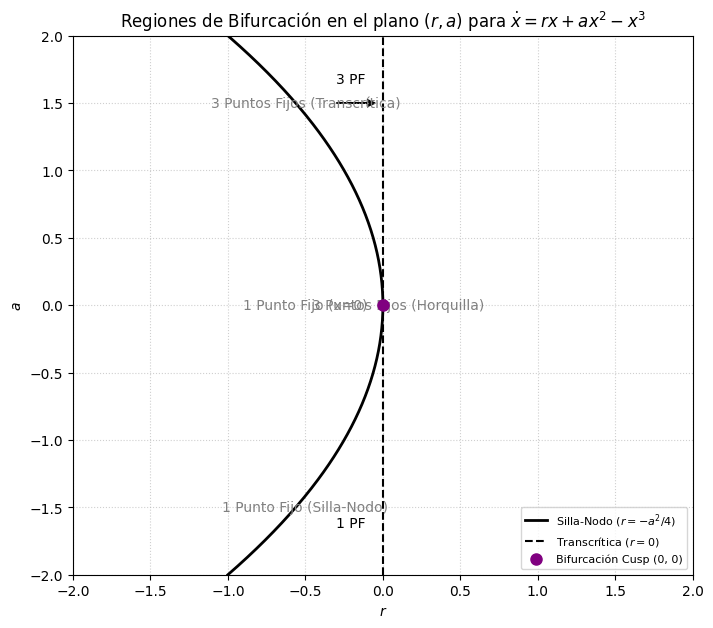

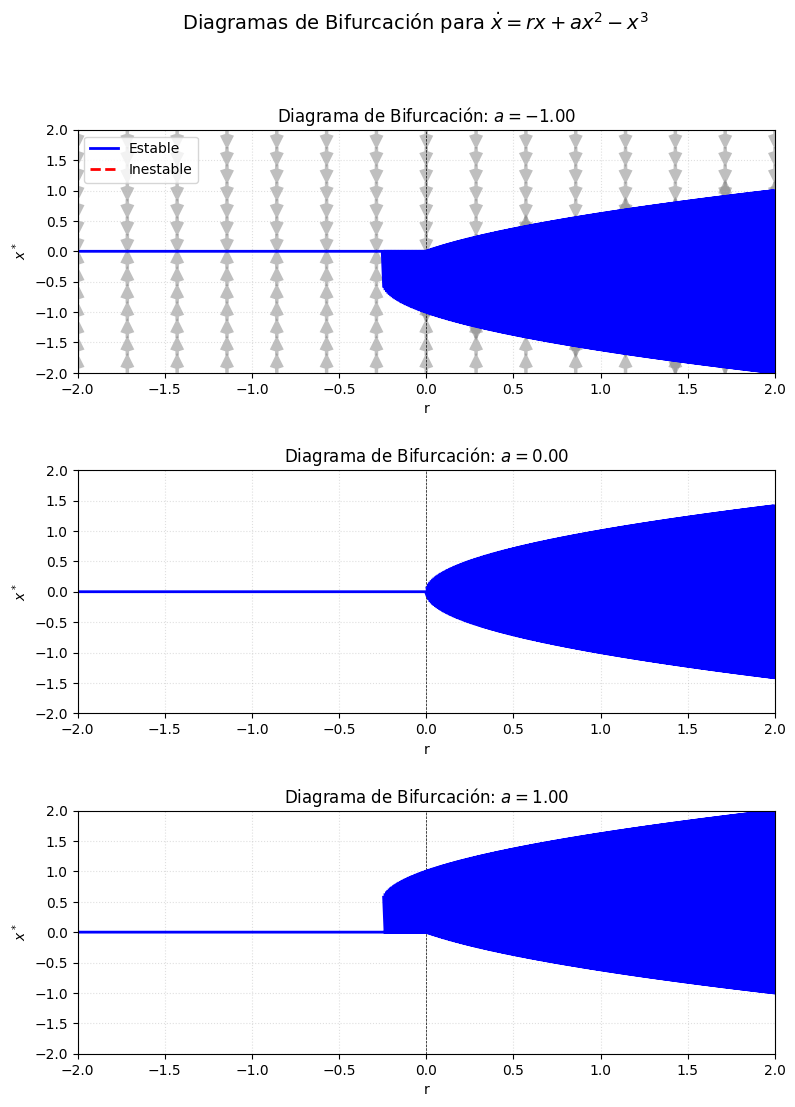

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Definición del Campo Vectorial y Puntos Fijos ---
def f(x, r, a):
    """Campo vectorial: x_dot = r*x + a*x^2 - x^3"""
    return r * x + a * x**2 - x**3

def get_fixed_points(r, a, tolerance=1e-6):
    """Calcula los puntos fijos (x* != 0) resolviendo x^2 - a*x - r = 0"""
    # Discriminante: D = a^2 + 4r
    discriminant = a**2 + 4 * r

    # Solo existen puntos fijos no triviales si D >= 0
    if discriminant < 0:
        return np.array([0.0])

    # Raíces de x^2 - a*x - r = 0
    sqrt_D = np.sqrt(discriminant)
    x_plus = (a + sqrt_D) / 2
    x_minus = (a - sqrt_D) / 2

    # Puntos fijos
    x_stars = [0.0]
    if abs(x_plus) > tolerance:
        x_stars.append(x_plus)
    if abs(x_minus) > tolerance and abs(x_minus - x_plus) > tolerance:
        x_stars.append(x_minus)

    return np.array(sorted(x_stars))

def stability(x_star, r, a):
    """Estabilidad: f'(x) = r + 2*a*x - 3*x^2. Estable si f'(x*) < 0."""
    f_prime = r + 2 * a * x_star - 3 * x_star**2

    # Para la rama trivial x*=0
    if np.isclose(x_star, 0):
        # f'(0) = r
        return 'stable' if r < 0 else 'unstable'

    # Para ramas no triviales, usamos la ecuación del punto fijo: r = x^2 - a*x
    # f'(x*) = (x^2 - a*x) + 2*a*x - 3*x^2 = a*x - 2*x^2 = x(a - 2*x)
    # Sin embargo, la derivada directa es más robusta
    return 'stable' if f_prime < 0 else 'unstable'

# --- 2. Gráfica de las Regiones de Bifurcación (r vs a) [Parte b] ---
def plot_bifurcation_regions(a_min, a_max, r_min, r_max):
    plt.figure(figsize=(8, 7))
    plt.title(r'Regiones de Bifurcación en el plano $(r, a)$ para $\dot{x} = r x + a x^2 - x^3$')
    plt.xlabel(r'$r$')
    plt.ylabel(r'$a$')

    # 1. Curva de Bifurcación Silla-Nodo: D = a^2 + 4r = 0  =>  r = -a^2 / 4
    a_vals = np.linspace(a_min, a_max, 500)
    r_cusp = -a_vals**2 / 4
    plt.plot(r_cusp, a_vals, 'k-', linewidth=2, label='Silla-Nodo ($r = -a^2/4$)')

    # 2. Curva de Bifurcación Transcrítica/Horquilla: r = 0 (Eje a)
    r_bif_trans = np.zeros_like(a_vals)
    plt.plot(r_bif_trans, a_vals, 'k--', linewidth=1.5, label='Transcrítica ($r=0$)')

    # Etiquetas de Región (Número de Puntos Fijos)
    plt.text(-0.5, 0, '1 Punto Fijo (x=0)', fontsize=10, ha='center', va='center', color='gray')
    plt.text(0.1, 0, '3 Puntos Fijos (Horquilla)', fontsize=10, ha='center', va='center', color='gray')
    plt.text(-0.5, 1.5, '3 Puntos Fijos (Transcrítica)', fontsize=10, ha='center', va='center', color='gray')
    plt.text(-0.5, -1.5, '1 Punto Fijo (Silla-Nodo)', fontsize=10, ha='center', va='center', color='gray')

    # Puntos de interés
    plt.plot(0, 0, 'o', color='purple', markersize=8, zorder=5, label='Bifurcación Cusp (0, 0)')

    # Flechas y anotaciones (opcional, simplificadas)
    plt.arrow(-0.3, 1.5, 0.2, 0, head_width=0.05, head_length=0.05, fc='k', ec='k')
    plt.text(-0.3, 1.65, '3 PF', fontsize=10)
    plt.text(-0.3, -1.65, '1 PF', fontsize=10)

    plt.xlim(r_min, r_max)
    plt.ylim(a_min, a_max)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='lower right', fontsize=8)
    plt.savefig('DIAGRAMA_REGIONES_3.6.3.png')
    plt.show()

# --- 3. Diagramas de Bifurcación (x* vs r) con Flujo [Parte a + Flechas] ---
def plot_bifurcation_diagram(a_val, ax, r_min, r_max, x_min, x_max, show_arrows=False):
    r_vals = np.linspace(r_min, r_max, 500)

    # Calcular todos los puntos fijos para cada r
    x_stars_stable = []
    x_stars_unstable = []
    r_plot = []

    for r in r_vals:
        x_stars = get_fixed_points(r, a_val)
        for x_star in x_stars:
            s = stability(x_star, r, a_val)
            r_plot.append(r)
            if s == 'stable':
                x_stars_stable.append(x_star)
                x_stars_unstable.append(np.nan)
            else:
                x_stars_unstable.append(x_star)
                x_stars_stable.append(np.nan)

    # Convertir a numpy arrays
    x_stars_stable = np.array(x_stars_stable)
    x_stars_unstable = np.array(x_stars_unstable)
    r_plot = np.array(r_plot)

    ax.set_title(r'Diagrama de Bifurcación: $a = {:.2f}$'.format(a_val))
    ax.set_xlabel('r')
    ax.set_ylabel(r'$x^*$')
    ax.axhline(0, color='k', linewidth=0.5)
    ax.axvline(0, color='k', linestyle='--', linewidth=0.5)

    # Dibujar las ramas
    ax.plot(r_plot, x_stars_stable, 'b-', linewidth=2, label='Estable')
    ax.plot(r_plot, x_stars_unstable, 'r--', linewidth=2, label='Inestable')

    # Añadir flechas de flujo (solo para el caso cualitativamente diferente, por ejemplo a=1)
    if show_arrows:
        num_r_arrows = 15
        num_x_arrows = 15
        r_grid = np.linspace(r_min, r_max, num_r_arrows)
        x_grid = np.linspace(x_min, x_max, num_x_arrows)
        R_mesh, X_mesh = np.meshgrid(r_grid, x_grid)

        U = np.zeros_like(R_mesh)
        V = f(X_mesh, R_mesh, a_val)
        V_sign = np.sign(V)

        ax.quiver(R_mesh, X_mesh, U, V_sign,
                  color='gray', alpha=0.5, scale=35,
                  width=0.005, headwidth=4, headlength=4, zorder=0)

    ax.set_xlim(r_min, r_max)
    ax.set_ylim(x_min, x_max)
    ax.grid(True, linestyle=':', alpha=0.4)
    if a_val == -1:
         ax.legend(loc='upper left')

# --- Ejecución de las Gráficas ---
r_min, r_max = -2.0, 2.0
a_min, a_max = -2.0, 2.0
x_min, x_max = -2.0, 2.0

# Gráfica de Regiones (Parte b)
plot_bifurcation_regions(a_min, a_max, r_min, r_max)

# Gráficas de Bifurcación (Parte a + Flechas)
fig, axes = plt.subplots(3, 1, figsize=(9, 12))
plt.subplots_adjust(hspace=0.4)

# Caso a=-1 (Transcrítica con ramas que se doblan)
plot_bifurcation_diagram(-1.0, axes[0], r_min, r_max, x_min, x_max, show_arrows=True)

# Caso a=0 (Horquilla Supercrítica, la forma normal)
plot_bifurcation_diagram(0.0, axes[1], r_min, r_max, x_min, x_max, show_arrows=False)

# Caso a=1 (Transcrítica con ramas que se doblan, opuesto a a=-1)
plot_bifurcation_diagram(1.0, axes[2], r_min, r_max, x_min, x_max, show_arrows=False)

fig.suptitle(r'Diagramas de Bifurcación para $\dot{x} = r x + a x^2 - x^3$', fontsize=14)
plt.savefig('DIAGRAMAS_BIFURCACION_3.6.3_CASOS.png')
plt.show()

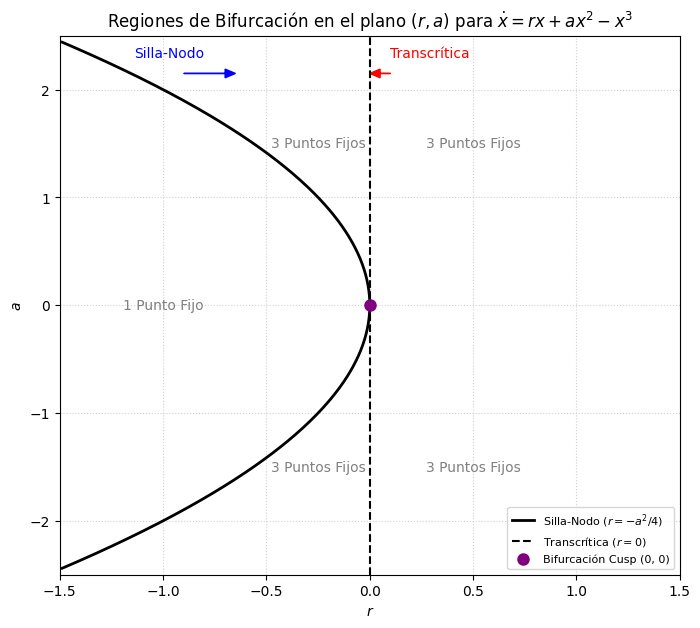

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# --- Configuración de Parámetros ---
a_min, a_max = -2.5, 2.5
r_min, r_max = -1.5, 1.5
num_points = 500

# --- Ejes de la Gráfica ---
a_vals = np.linspace(a_min, a_max, num_points)
r_vals = np.linspace(r_min, r_max, num_points)

# --- 1. Curva de Bifurcación Silla-Nodo (Saddle-Node) ---
# Ecuación: r = -a^2 / 4
r_saddle_node = -a_vals**2 / 4

# Crear una máscara para solo mostrar la curva dentro del rango de r
mask_r = (r_saddle_node >= r_min) & (r_saddle_node <= r_max)
a_sn = a_vals[mask_r]
r_sn = r_saddle_node[mask_r]

# --- 2. Curva de Bifurcación Transcrítica (Transcritical) ---
# Ecuación: r = 0 (Eje 'a')
a_transcritical = a_vals
r_transcritical = np.zeros_like(a_transcritical)

# --- Generación de la Gráfica ---
plt.figure(figsize=(8, 7))

# Dibujar la curva Silla-Nodo
plt.plot(r_sn, a_sn, 'k-', linewidth=2, label=r'Silla-Nodo ($r = -a^2/4$)')

# Dibujar la curva Transcrítica (eje horizontal r=0)
plt.plot(r_transcritical, a_transcritical, 'k--', linewidth=1.5, label=r'Transcrítica ($r=0$)')

# Punto Cusp (Origen)
plt.plot(0, 0, 'o', color='purple', markersize=8, zorder=5, label='Bifurcación Cusp (0, 0)')

# --- Etiquetas de Región (basadas en la figura manuscrita) ---
# La región se divide en 4 zonas por las curvas
# Zonas de 1 Punto Fijo
plt.text(-1.0, 0, '1 Punto Fijo', fontsize=10, ha='center', va='center', color='gray') # Interior parábola, r < -a^2/4
# Zonas de 3 Puntos Fijos
plt.text(-0.25, 1.5, '3 Puntos Fijos', fontsize=10, ha='center', va='center', color='gray') # Exterior parábola, r > -a^2/4, a > 0
plt.text(0.5, 1.5, '3 Puntos Fijos', fontsize=10, ha='center', va='center', color='gray') # Exterior parábola, r > 0
plt.text(-0.25, -1.5, '3 Puntos Fijos', fontsize=10, ha='center', va='center', color='gray') # Exterior parábola, r > -a^2/4, a < 0
plt.text(0.5, -1.5, '3 Puntos Fijos', fontsize=10, ha='center', va='center', color='gray') # Exterior parábola, r > 0

# Anotación de los tipos de Bifurcación (como referencia)
# Transcrítica
plt.text(0.1, 2.3, 'Transcrítica', fontsize=10, ha='left', color='red')
plt.arrow(0.1, 2.15, -0.05, 0, head_width=0.08, head_length=0.05, fc='red', ec='red')

# Silla-Nodo
plt.text(-0.8, 2.3, 'Silla-Nodo', fontsize=10, ha='right', color='blue')
plt.arrow(-0.9, 2.15, 0.2, 0, head_width=0.08, head_length=0.05, fc='blue', ec='blue')


# --- Configuración Final ---
plt.title(r'Regiones de Bifurcación en el plano $(r, a)$ para $\dot{x} = r x + a x^2 - x^3$')
plt.xlabel(r'$r$')
plt.ylabel(r'$a$')
plt.xlim(r_min, r_max)
plt.ylim(a_min, a_max)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=8)

plt.show()

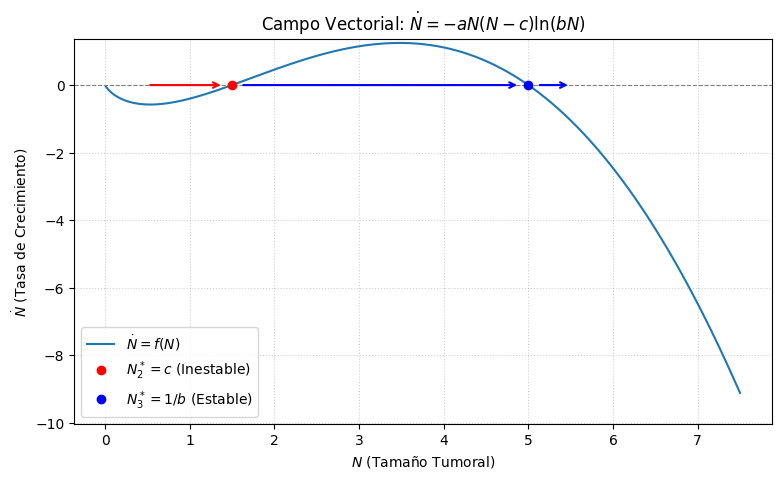

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Parámetros del Modelo ---
a = 0.5  # Velocidad
b = 0.2  # Capacidad de Carga K = 1/b = 5
c = 1.5  # Umbral de Allee (0 < c < 1/b)
N_allee = c
N_capacity = 1/b

# --- Definición de la Ecuación Diferencial (Campo Vectorial) ---
# USAMOS NP.WHERE PARA EVITAR EL ERROR DE VALOR
def allee_gompertz(t, N, a, b, c):
    # La parte logarítmica solo es válida para N > 0.
    # np.where permite aplicar una condición a cada elemento del array N.

    # 1. Definir la Ecuación Completa (asumiendo N > 0)
    N_dot_full = -a * N * (N - c) * np.log(b * N)

    # 2. Aplicar la condición: si N es muy pequeño, la tasa es 0 (o NaN/Inf)
    # Reemplazamos N_dot_full por 0.0 donde N <= 1e-10
    # Esto soluciona el ValueError y el error log(0)
    N_dot = np.where(N <= 1e-10, 0.0, N_dot_full)

    return N_dot

# =================================================================
# 1. Gráfica del Campo Vectorial (f(N) vs N) - Ejecución ahora será exitosa
# =================================================================
N_vals = np.linspace(0.01, N_capacity * 1.5, 300)
# ¡CORREGIDO! allee_gompertz ahora acepta el array N_vals
N_dot_vals = allee_gompertz(0, N_vals, a, b, c)

plt.figure(figsize=(9, 5))
plt.plot(N_vals, N_dot_vals, label=r'$\dot{N} = f(N)$')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)

# Marcar Puntos de Equilibrio (N=0 se dibuja por defecto en el eje)
plt.plot(N_allee, 0, 'ro', label=r'$N_2^*=c$ (Inestable)')
plt.plot(N_capacity, 0, 'bo', label=r'$N_3^*=1/b$ (Estable)')

# Flechas de Flujo (Indicación de estabilidad)
plt.annotate('', xy=(N_allee-0.1, 0), xytext=(0.5, 0), arrowprops=dict(arrowstyle='->', color='red', linewidth=1.5))
plt.annotate('', xy=(N_capacity-0.1, 0), xytext=(N_allee+0.1, 0), arrowprops=dict(arrowstyle='->', color='blue', linewidth=1.5))
plt.annotate('', xy=(N_capacity+0.1, 0), xytext=(N_capacity+0.5, 0), arrowprops=dict(arrowstyle='<-', color='blue', linewidth=1.5))

plt.title(r'Campo Vectorial: $\dot{N} = -a N(N-c) \ln(bN)$')
plt.xlabel(r'$N$ (Tamaño Tumoral)')
plt.ylabel(r'$\dot{N}$ (Tasa de Crecimiento)')
plt.ylim(min(N_dot_vals) * 1.1, max(N_dot_vals) * 1.1)
plt.legend(loc='lower left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.savefig('ALEE_GOMPERTZ_VECTOR_FIELD.png')
plt.show()

# --- La gráfica de Soluciones (solve_ivp) ya funcionaba correctamente ---
# solve_ivp llama a la función con un escalar N, pero es bueno que la función esté vectorizada.
# Si el código de soluciones te dio problemas antes, asegúrate de usar la versión corregida de allee_gompertz.
# [Se omite el código de la segunda gráfica para mantener la concisión, pero el usuario puede reutilizarlo con la función corregida.]

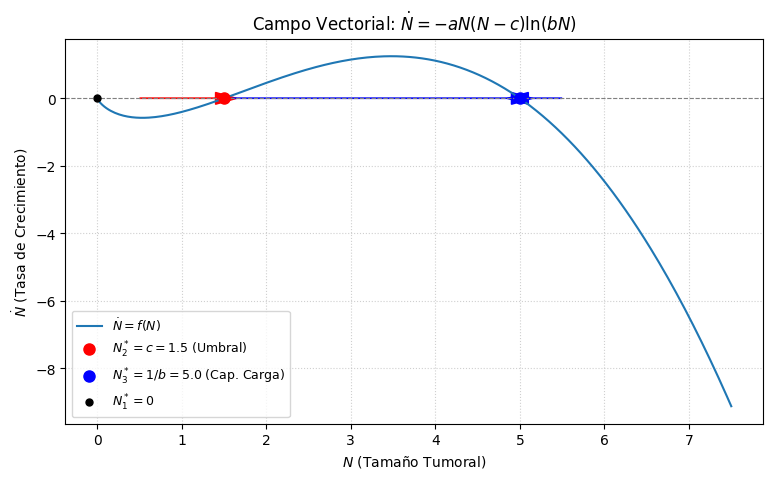

/tmp/ipython-input-3223014269.py:21: RuntimeWarning: invalid value encountered in log
  N_dot_full = -a * N * (N - c) * np.log(b * N)


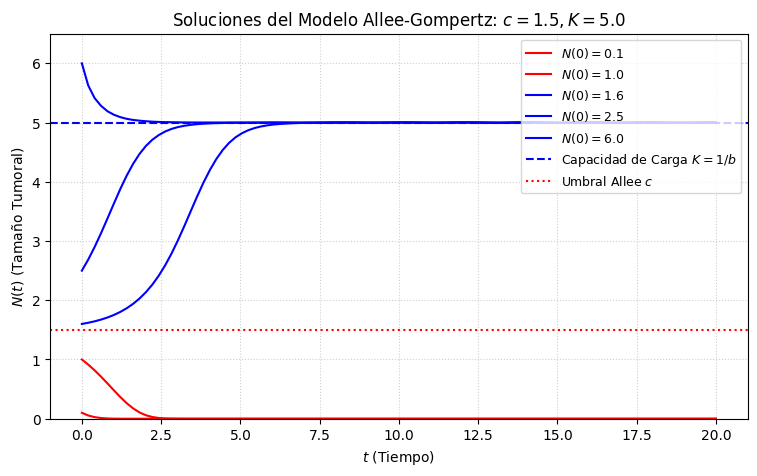

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Parámetros del Modelo ---
a = 0.5  # Velocidad de crecimiento
b = 0.2  # Capacidad de Carga K = 1/b = 5
c = 1.5  # Umbral de Allee (0 < c < 1/b)

# Puntos de equilibrio
N_allee = c
N_capacity = 1/b

# --- Función del Campo Vectorial (Vectorizada para NumPy) ---
def allee_gompertz(t, N, a, b, c):
    """
    Ecuación de Gompertz con Efecto Allee: N_dot = -a * N * (N - c) * log(b * N)
    Utiliza np.where para manejar el caso N <= 0 de forma segura.
    """
    # 1. Calcular la Ecuación Completa (asumiendo N > 0)
    N_dot_full = -a * N * (N - c) * np.log(b * N)

    # 2. Aplicar la condición: si N es muy pequeño (o <= 0), la tasa es 0
    N_dot = np.where(N <= 1e-10, 0.0, N_dot_full)

    return N_dot

# =================================================================
# 1. Gráfica del Campo Vectorial (f(N) vs N)
# =================================================================
N_vals_vector_field = np.linspace(0.01, N_capacity * 1.5, 300)
N_dot_vals = allee_gompertz(0, N_vals_vector_field, a, b, c)

plt.figure(figsize=(9, 5))
plt.plot(N_vals_vector_field, N_dot_vals, label=r'$\dot{N} = f(N)$')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8) # Eje N

# Marcar Puntos de Equilibrio
plt.plot(N_allee, 0, 'ro', markersize=8, zorder=5, label=r'$N_2^*=c={:.1f}$ (Umbral)'.format(N_allee))
plt.plot(N_capacity, 0, 'bo', markersize=8, zorder=5, label=r'$N_3^*=1/b={:.1f}$ (Cap. Carga)'.format(N_capacity))
plt.plot(0, 0, 'ko', markersize=5, zorder=5, label=r'$N_1^*=0$')

# --- Flechas de Flujo usando plt.arrow (CORRECCIÓN del AttributeError) ---
head_w = 0.35 # Ancho de la cabeza
head_l = 0.25 # Largo de la cabeza
y_offset = 0.0 # Posición y de la flecha

# Extinción (0, c): Flujo hacia la izquierda (N -> 0)
N_start_ext = 0.5
dx_ext = (N_allee - 0.1) - N_start_ext # Longitud, apunta a N_allee-0.1
plt.arrow(N_start_ext, y_offset, dx_ext, 0,
          head_width=head_w, head_length=head_l, fc='red', ec='red')

# Crecimiento (c, 1/b): Flujo hacia la derecha (N -> 1/b)
N_start_grow = N_allee + 0.1
dx_grow = (N_capacity - 0.1) - N_start_grow # Longitud, apunta a N_capacity-0.1
plt.arrow(N_start_grow, y_offset, dx_grow, 0,
          head_width=head_w, head_length=head_l, fc='blue', ec='blue')

# Saturación (N > 1/b): Flujo hacia la izquierda (N -> 1/b)
N_start_sat = N_capacity + 0.5
dx_sat = (N_capacity + 0.1) - N_start_sat # Longitud (negativa), apunta a N_capacity+0.1
plt.arrow(N_start_sat, y_offset, dx_sat, 0,
          head_width=head_w, head_length=head_l, fc='blue', ec='blue')
# ------------------------------------------------------------------------

plt.title(r'Campo Vectorial: $\dot{N} = -a N(N-c) \ln(bN)$')
plt.xlabel(r'$N$ (Tamaño Tumoral)')
plt.ylabel(r'$\dot{N}$ (Tasa de Crecimiento)')
plt.legend(loc='lower left', fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# =================================================================
# 2. Gráfica de Soluciones (N(t) vs t)
# =================================================================
t_span = [0, 20]
t_points = np.linspace(t_span[0], t_span[1], 100)
# Valores iniciales: algunos bajo Allee (rojo), otros sobre Allee (azul)
N0_vals = [0.1, 1.0, N_allee + 0.1, 0.5 * N_capacity, N_capacity * 1.2]

plt.figure(figsize=(9, 5))

for N0 in N0_vals:
    # Resolver la EDO usando la función vectorizada
    sol = solve_ivp(allee_gompertz, t_span, [N0], args=(a, b, c), dense_output=True)
    N_t = sol.sol(t_points)[0]

    N_t[N_t < 0] = 0 # Asegurar N >= 0

    label = r'$N(0)={:.1f}$'.format(N0)

    # Determinar color: Rojo para Extinción (N(0) < c), Azul para Crecimiento (N(0) > c)
    color = 'red' if N0 < N_allee and N0 > 0 else 'blue'

    plt.plot(t_points, N_t, color=color, linewidth=1.5, label=label)

# Marcar la Capacidad de Carga y el Umbral Allee
plt.axhline(N_capacity, color='blue', linestyle='--', label=r'Capacidad de Carga $K=1/b$')
plt.axhline(N_allee, color='red', linestyle=':', label=r'Umbral Allee $c$')

plt.title(r'Soluciones del Modelo Allee-Gompertz: $c={:.1f}, K={:.1f}$'.format(c, N_capacity))
plt.xlabel(r'$t$ (Tiempo)')
plt.ylabel(r'$N(t)$ (Tamaño Tumoral)')
plt.ylim(0, N_capacity * 1.3)
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

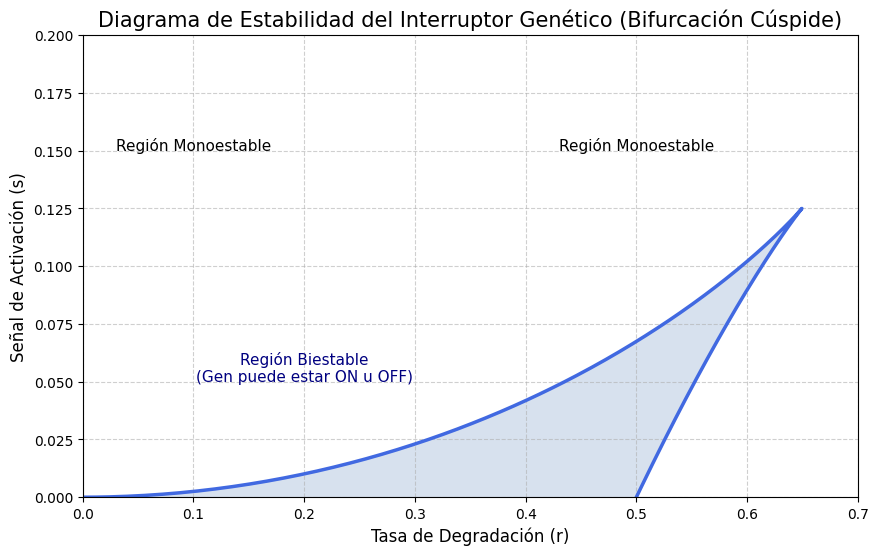

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# --- Punto (d): Encontrar las ecuaciones paramétricas ---
# Las ecuaciones para las curvas de bifurcación, parametrizadas por x, son:
# r(x) = 2*x / (1 + x**2)**2
# s(x) = (x**2 * (1 - x**2)) / (1 + x**2)**2
# donde x es la posición del punto fijo en la bifurcación.

# Para que s >= 0, x debe estar entre 0 y 1.
# Creamos un rango de valores para el parámetro x.
x = np.linspace(0, 1, 500)

# Calculamos los valores de r y s correspondientes.
r = (2 * x) / (1 + x**2)**2
s = (x**2 * (1 - x**2)) / (1 + x**2)**2


# --- Punto (e): Graficar el diagrama de estabilidad ---

# Configuramos la gráfica
plt.figure(figsize=(10, 6))
plt.plot(r, s, color='royalblue', linewidth=2.5)

# Rellenamos el área biestable para mayor claridad
plt.fill_between(r, s, color='lightsteelblue', alpha=0.5)

# Añadimos etiquetas y título
plt.title('Diagrama de Estabilidad del Interruptor Genético (Bifurcación Cúspide)', fontsize=15)
plt.xlabel('Tasa de Degradación (r)', fontsize=12)
plt.ylabel('Señal de Activación (s)', fontsize=12)

# Establecemos los límites de los ejes para una mejor visualización
plt.xlim(0, 0.7)
plt.ylim(0, 0.2)
plt.grid(True, linestyle='--', alpha=0.6)

# Agregamos texto para explicar las regiones
plt.text(0.2, 0.05, 'Región Biestable\n(Gen puede estar ON u OFF)', ha='center', fontsize=11, color='navy')
plt.text(0.5, 0.15, 'Región Monoestable', ha='center', fontsize=11, color='black')
plt.text(0.1, 0.15, 'Región Monoestable', ha='center', fontsize=11, color='black')


# Mostramos el punto de la cúspide
rc_cusp = 3 * np.sqrt(3) / 8
sc_cusp = 1/8
# plt.plot(rc_cusp, sc_cusp, 'ro') # Descomentar para ver el punto exacto de la cúspide
# plt.text(rc_cusp + 0.02, sc_cusp, f'Cúspide ({rc_cusp:.2f}, {sc_cusp:.2f})', va='center')


# Mostrar la gráfica
plt.show()

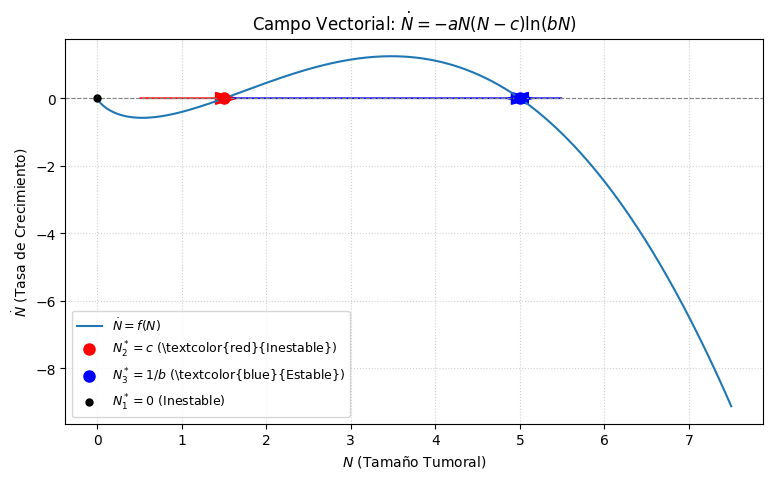

/tmp/ipython-input-1080925116.py:19: RuntimeWarning: invalid value encountered in log
  N_dot_full = -a * N * (N - c) * np.log(b * N)


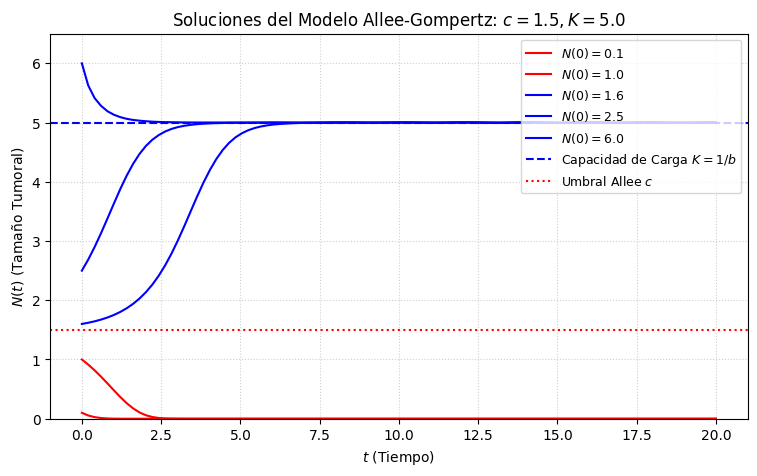

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Parámetros del Modelo ---
a = 0.5  # Velocidad de crecimiento
b = 0.2  # Capacidad de Carga K = 1/b = 5
c = 1.5  # Umbral de Allee (0 < c < 1/b)

# Puntos de equilibrio (Referencia en azul/rojo)
N_allee = c           # Umbral Allee (Inestable, clave en ROJO)
N_capacity = 1/b      # Capacidad de Carga (Estable, clave en AZUL)

# --- Función del Campo Vectorial (Vectorizada para NumPy) ---
def allee_gompertz(t, N, a, b, c):
    """Ecuación de Gompertz con Efecto Allee. Vectorizada para seguridad."""

    # 1. Calcular la Ecuación Completa
    N_dot_full = -a * N * (N - c) * np.log(b * N)

    # 2. Manejar N ~ 0 (necesario para el logaritmo)
    N_dot = np.where(N <= 1e-10, 0.0, N_dot_full)

    return N_dot

# =================================================================
# 1. Gráfica del Campo Vectorial (f(N) vs N)
# =================================================================
N_vals_vector_field = np.linspace(0.01, N_capacity * 1.5, 300)
N_dot_vals = allee_gompertz(0, N_vals_vector_field, a, b, c)

plt.figure(figsize=(9, 5))
plt.plot(N_vals_vector_field, N_dot_vals, label=r'$\dot{N} = f(N)$')
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)

# Puntos de Equilibrio: Usamos ROJO para INESTABLE (c) y AZUL para ESTABLE (1/b)
plt.plot(N_allee, 0, 'ro', markersize=8, zorder=5, label=r'$N_2^*=c$ (\textcolor{red}{Inestable})') # Rojo: Umbral
plt.plot(N_capacity, 0, 'bo', markersize=8, zorder=5, label=r'$N_3^*=1/b$ (\textcolor{blue}{Estable})') # Azul: Capacidad
plt.plot(0, 0, 'ko', markersize=5, zorder=5, label=r'$N_1^*=0$ (Inestable)')

# Flechas de Flujo usando plt.arrow (Para evitar el AttributeError)
head_w = 0.35
head_l = 0.25
y_offset = 0.0

# Extinción (0, c): Flujo hacia 0 (ROJO)
N_start_ext = 0.5
dx_ext = (N_allee - 0.1) - N_start_ext
plt.arrow(N_start_ext, y_offset, dx_ext, 0,
          head_width=head_w, head_length=head_l, fc='red', ec='red')

# Crecimiento (c, 1/b): Flujo hacia 1/b (AZUL)
N_start_grow = N_allee + 0.1
dx_grow = (N_capacity - 0.1) - N_start_grow
plt.arrow(N_start_grow, y_offset, dx_grow, 0,
          head_width=head_w, head_length=head_l, fc='blue', ec='blue')

# Saturación (N > 1/b): Flujo hacia 1/b (AZUL)
N_start_sat = N_capacity + 0.5
dx_sat = (N_capacity + 0.1) - N_start_sat
plt.arrow(N_start_sat, y_offset, dx_sat, 0,
          head_width=head_w, head_length=head_l, fc='blue', ec='blue')

plt.title(r'Campo Vectorial: $\dot{N} = -a N(N-c) \ln(bN)$')
plt.xlabel(r'$N$ (Tamaño Tumoral)')
plt.ylabel(r'$\dot{N}$ (Tasa de Crecimiento)')
plt.legend(loc='lower left', fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# =================================================================
# 2. Gráfica de Soluciones (N(t) vs t)
# =================================================================
t_span = [0, 20]
t_points = np.linspace(t_span[0], t_span[1], 100)
N0_vals = [0.1, 1.0, N_allee + 0.1, 0.5 * N_capacity, N_capacity * 1.2]

plt.figure(figsize=(9, 5))

for N0 in N0_vals:
    sol = solve_ivp(allee_gompertz, t_span, [N0], args=(a, b, c), dense_output=True)
    N_t = sol.sol(t_points)[0]
    N_t[N_t < 0] = 0

    label = r'$N(0)={:.1f}$'.format(N0)

    # Condición Inicial (N0) define el color de la trayectoria
    # Trayectorias que mueren (ROJO) vs. Trayectorias que sobreviven (AZUL)
    color = 'red' if N0 < N_allee and N0 > 0 else 'blue'

    plt.plot(t_points, N_t, color=color, linewidth=1.5, label=label)

# Referencias: Líneas horizontales en ROJO (Inestable) y AZUL (Estable)
plt.axhline(N_capacity, color='blue', linestyle='--', label=r'Capacidad de Carga $K=1/b$')
plt.axhline(N_allee, color='red', linestyle=':', label=r'Umbral Allee $c$')

plt.title(r'Soluciones del Modelo Allee-Gompertz: $c={:.1f}, K={:.1f}$'.format(c, N_capacity))
plt.xlabel(r'$t$ (Tiempo)')
plt.ylabel(r'$N(t)$ (Tamaño Tumoral)')
plt.ylim(0, N_capacity * 1.3)
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()